Running F01 (dim=1)...


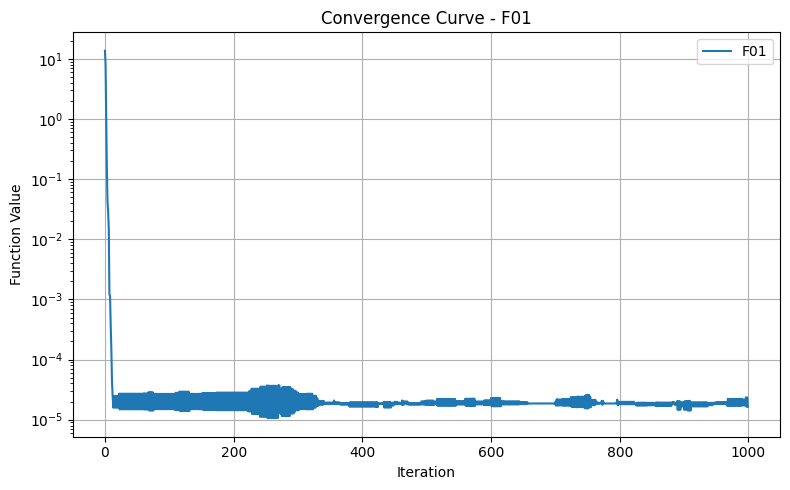

Running F02 (dim=1)...


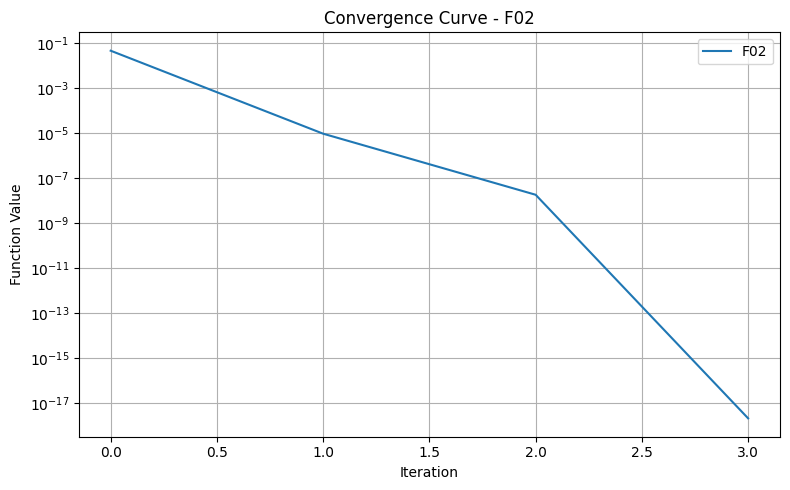

Running F03 (dim=1)...
Running F04 (dim=2)...


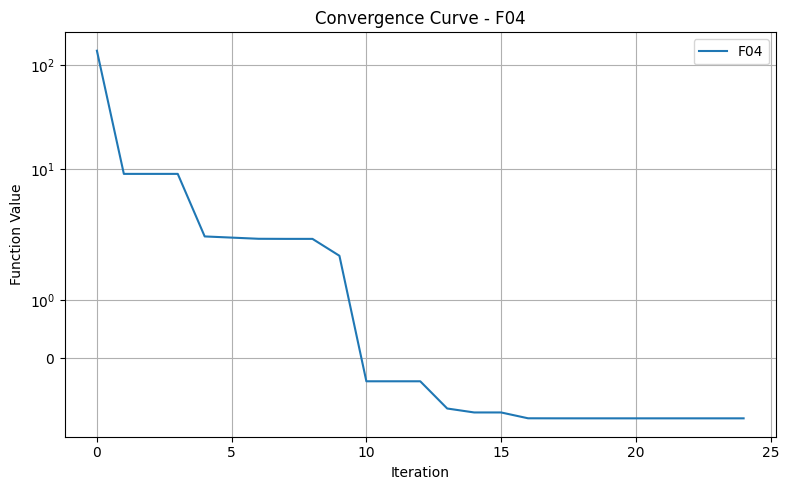

Running F05 (dim=2)...


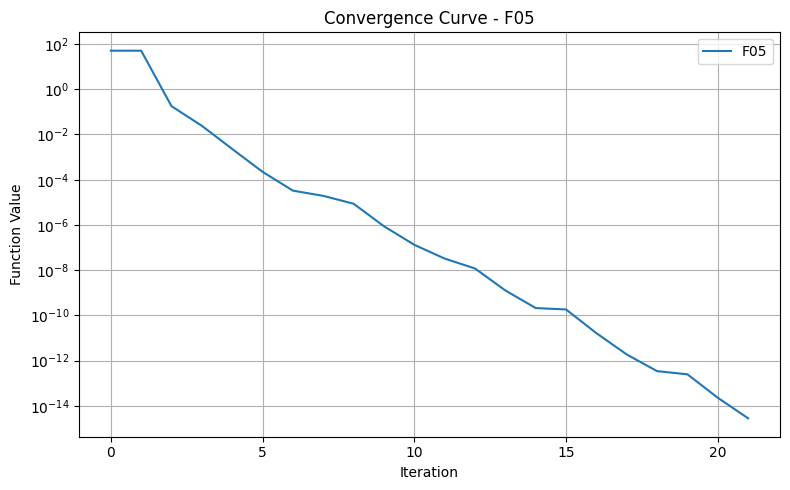

Running F06 (dim=3)...


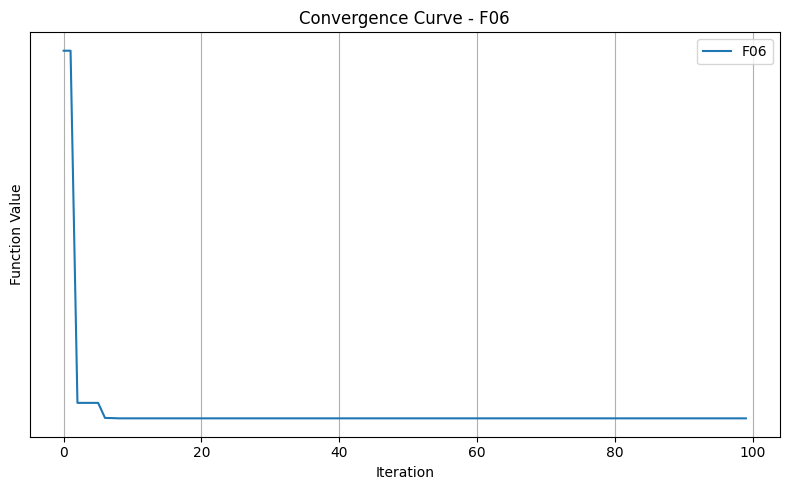

Running F07 (dim=2)...


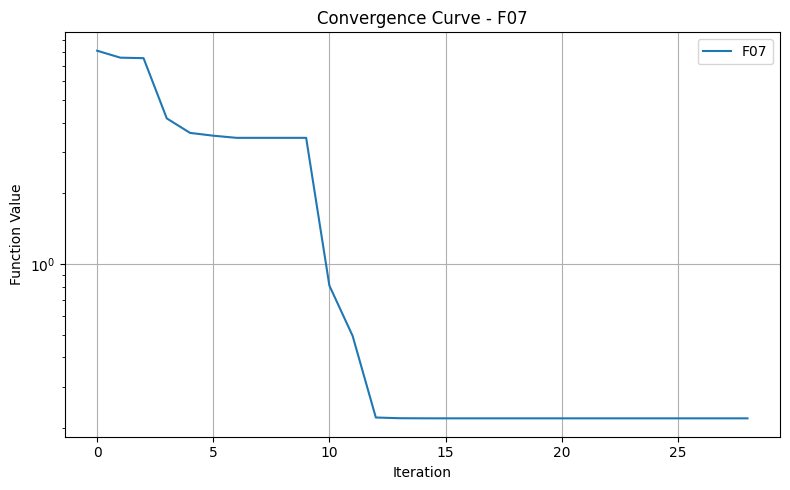

Running F08 (dim=3)...


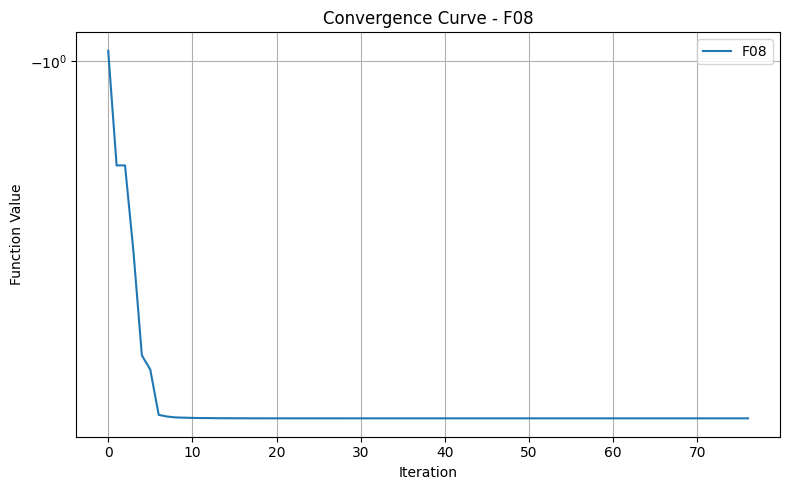

Running F09 (dim=2)...


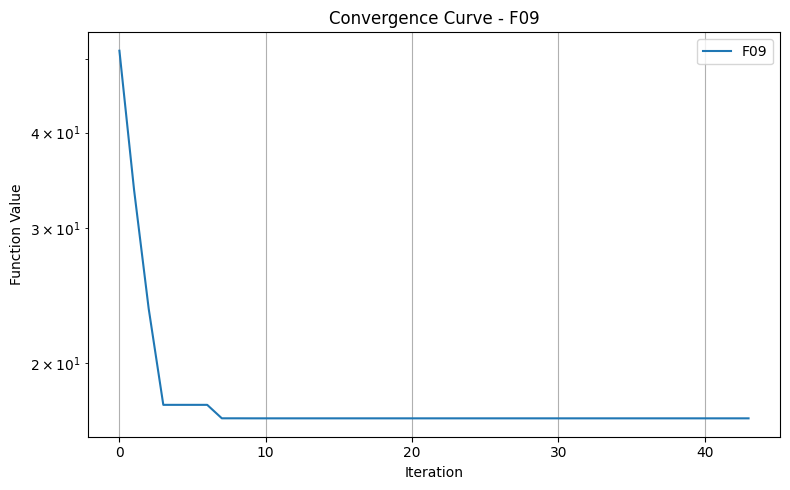

Running F10 (dim=10)...


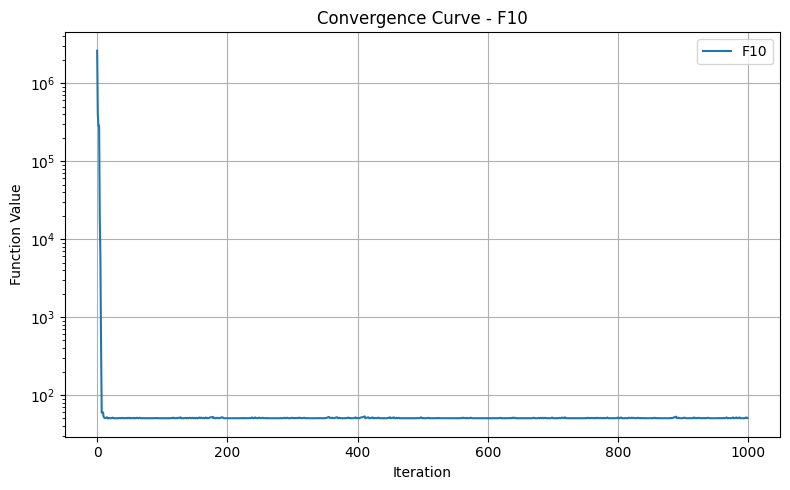

Running F11 (dim=2)...


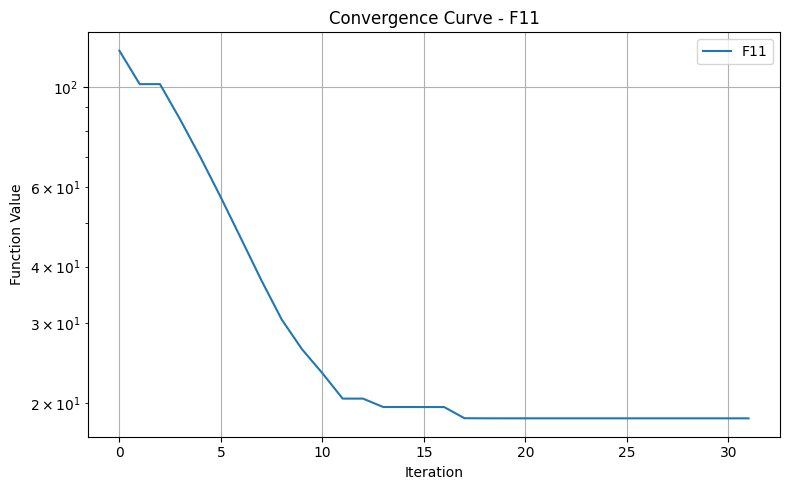

Running F12 (dim=5)...


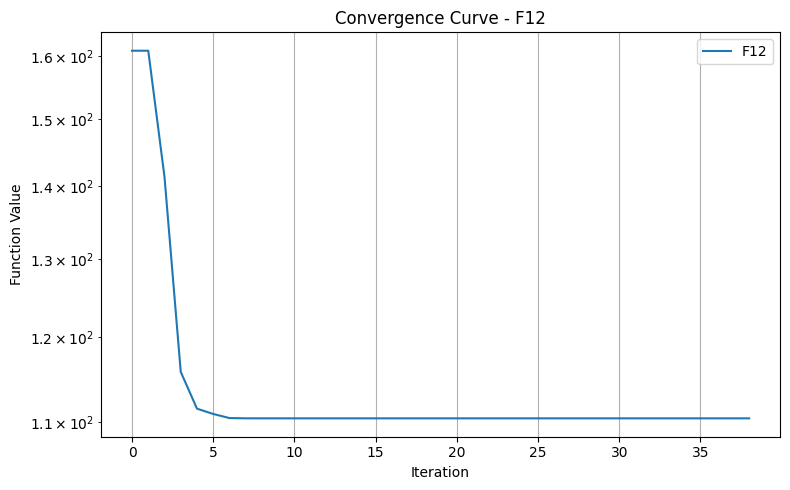


--- Benchmark Results ---
                  Best          Mean        Median         Worst           STD
Function                                                                      
F01       3.727170e-06  3.193891e-05  2.733677e-05  7.498239e-05  1.891755e-05
F02       2.148835e-18  3.834695e-11  5.695549e-12  2.690629e-10  7.006171e-11
F03       1.142071e-83  1.655950e-10  2.327815e-24  2.769654e-09  5.529319e-10
F04      -1.031628e+00 -1.638960e-01 -1.031628e+00  2.104250e+00  1.285535e+00
F05       7.057779e-16  4.275601e-15  3.331673e-15  1.219209e-14  2.762234e-15
F06      -2.709094e+03 -9.336064e+02 -5.463146e+02 -2.335700e+01  9.808145e+02
F07       1.447124e-15  1.896010e+00  4.944254e-01  2.150495e+01  4.030898e+00
F08      -3.000000e+00 -3.000000e+00 -3.000000e+00 -3.000000e+00  6.833839e-14
F09       3.979831e+00  5.375990e+01  5.621448e+01  1.124276e+02  3.051317e+01
F10       3.154688e+01  5.092824e+01  4.993779e+01  7.901116e+01  1.040271e+01
F11       1.847585e+01  1

In [6]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
from scipy.optimize import minimize, Bounds

# --- Custom Benchmark Functions (with fixes) ---
def Five_Uneven_Peak_Trap(x):
    x = x[0]
    if x < 2.5:
        return 80 * (2.5 - x)
    elif x < 5:
        return 64 * (x - 2.5)
    elif x < 7.5:
        return 64 * (7.5 - x)
    elif x < 12.5:
        return 28 * (x - 7.5)
    else:
        return 28 * (15 - x)

def Equal_Maxima(x):
    x = x[0]
    return np.sin(5 * np.pi * x) ** 6

def Uneven_Decreasing_Maxima(x):
    x = x[0]
    if x < 0:
        return np.inf
    return np.exp(-2 * np.log(2) * ((x - 0.08) / 0.854) ** 2) * \
           np.sin(5 * np.pi * (x ** 0.75 - 0.05)) ** 6

def Six_Hump_Camel_Back(x):
    x1, x2 = x
    return (4 - 2.1 * x1**2 + x1**4 / 3) * x1**2 + x1 * x2 + (-4 + 4 * x2**2) * x2**2

def Himmelblau(x):
    x1, x2 = x
    return (x1**2 + x2 - 11) ** 2 + (x1 + x2**2 - 7) ** 2

def Shubert(x):
    x = np.asarray(x)
    result = 1
    for i in range(len(x)):
        s = 0
        for j in range(1, 6):
            s += j * np.cos((j + 1) * x[i] + j)
        result *= s
    return result

def Composition_Function_1(x):
    return np.sum((x - 1)**2) + np.sum(np.sin(3 * np.pi * x)**2)

def Vincent(x):
    x = np.asarray(x)
    if np.any(x <= 0):
        return np.inf
    return -np.sum(np.sin(10 * np.log(x)))

def Modified_Rastrigin_All_Global_Optima(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum((x - 0.1)**2 - 10 * np.cos(2 * np.pi * (x - 0.1)))

def Composition_Function_4(x):
    return np.sum(np.abs(x)) + np.prod(np.abs(x))

def Composition_Function_2(x):
    return np.sum((x + 1)**2) + np.sum(np.cos(2 * np.pi * (x + 1))) + 10 * len(x)

def Composition_Function_3(x):
    return np.sum(x**2 - 10 * np.cos(2 * np.pi * x)) + 10 * len(x)

# --- Benchmark Function Mapping ---
benchmark_functions = {
    "F01": Five_Uneven_Peak_Trap,
    "F02": Equal_Maxima,
    "F03": Uneven_Decreasing_Maxima,
    "F04": Six_Hump_Camel_Back,
    "F05": Himmelblau,
    "F06": Shubert,
    "F07": Composition_Function_1,
    "F08": Vincent,
    "F09": Modified_Rastrigin_All_Global_Optima,
    "F10": Composition_Function_4,
    "F11": Composition_Function_2,
    "F12": Composition_Function_3
}

# --- Numerical Gradient ---
def numerical_gradient(func, x, eps=1e-8):
    grad = np.zeros_like(x)
    for i in range(len(x)):
        x1 = np.copy(x)
        x2 = np.copy(x)
        x1[i] += eps
        x2[i] -= eps
        f1 = func(x1)
        f2 = func(x2)
        if np.isfinite(f1) and np.isfinite(f2):
            grad[i] = (f1 - f2) / (2 * eps)
        else:
            grad[i] = 0
    return grad

# --- Powell's Dog Leg with Chaos ---
def powells_dog_leg_with_chaos(func, grad_func, x0, trust_radius=1.0, tol=1e-6, max_iter=1000, chaotic_prob=0.1):
    x = x0.copy()
    convergence_curve = []
    for _ in range(max_iter):
        grad = grad_func(x)
        if np.linalg.norm(grad) < tol:
            break

        hess = np.eye(len(x))
        newton_step = -np.linalg.solve(hess, grad)
        cauchy_point = -trust_radius * grad / np.linalg.norm(grad)

        if np.linalg.norm(newton_step) <= trust_radius:
            p = newton_step
        elif np.linalg.norm(cauchy_point) >= trust_radius:
            p = cauchy_point
        else:
            u = cauchy_point - newton_step
            a = np.dot(u, u)
            b = 2 * np.dot(u, newton_step)
            c = np.dot(newton_step, newton_step) - trust_radius**2
            discriminant = b**2 - 4 * a * c

            if not np.isfinite(discriminant) or discriminant < 0:
                p = cauchy_point
            else:
                tau = (-b + np.sqrt(discriminant)) / (2 * a)
                p = newton_step + tau * u

        if random.random() < chaotic_prob:
            chaos = np.random.rand(len(x))
            p += (chaos - 0.5) * 0.1

        alpha = 1.0
        while func(x + alpha * p) > func(x) + 1e-4 * alpha * np.dot(grad, p):
            alpha *= 0.5
            if alpha < 1e-6:
                break

        x = x + alpha * p
        convergence_curve.append(func(x))

    return x, convergence_curve

# --- Run Single Benchmark ---
def run_benchmark(func, dim, runs=30, low=0.1, high=10):
    results = []
    convergence = None
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, curve = powells_dog_leg_with_chaos(func, lambda x: numerical_gradient(func, x), x0)
            val = func(result)
            if np.isfinite(val):
                results.append(val)
                if convergence is None:
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    dim_dict = {
        "F01": 1, "F02": 1, "F03": 1,
        "F04": 2, "F05": 2, "F06": 3,
        "F07": 2, "F08": 3, "F09": 2,
        "F10": 10, "F11": 2, "F12": 5
    }
    for name, func in benchmark_functions.items():
        d = dim_dict.get(name, dim)
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence is not None and len(convergence) > 0:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# --- Save Excel ---
output_path = 'Benchmark_Custom_PDL.xlsx'
results.to_excel(output_path)
print(f"\n✅ Results saved to {output_path}")

Running F01 (dim=1)...


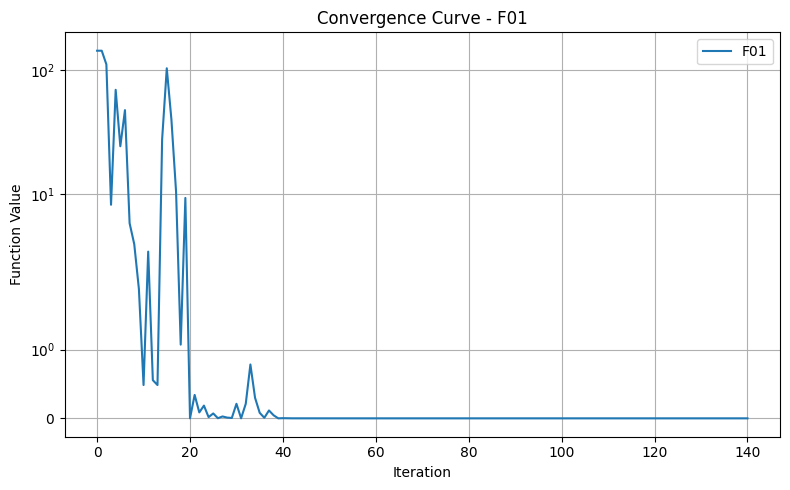

Running F02 (dim=1)...


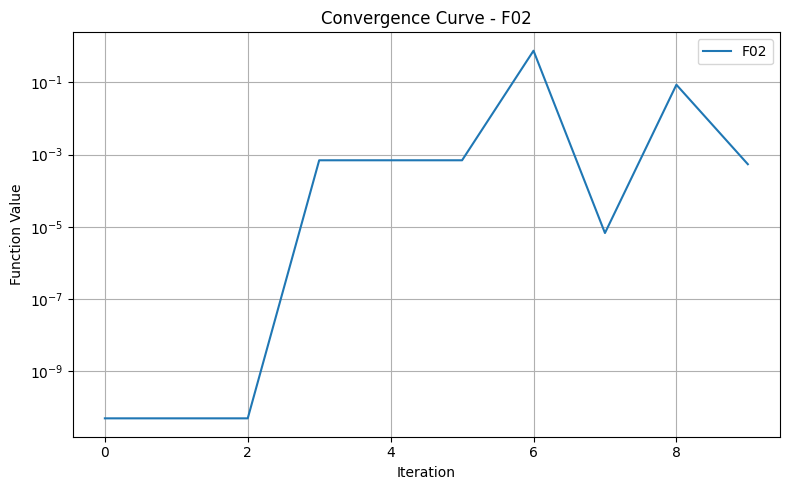

Running F03 (dim=1)...


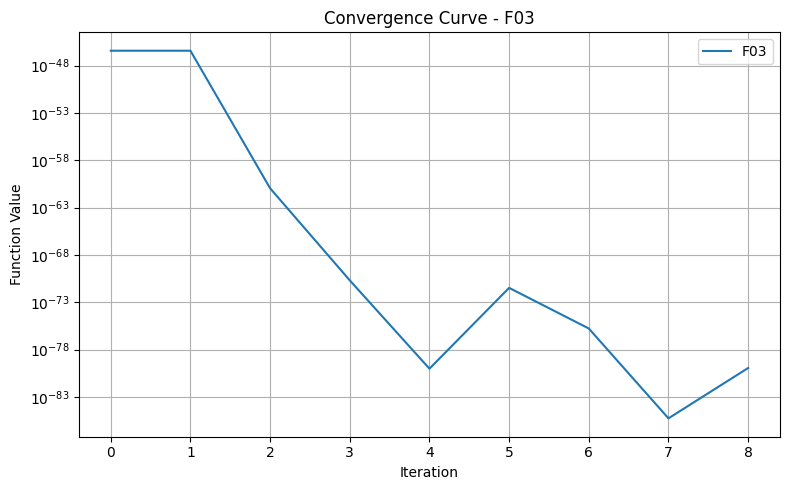

Running F04 (dim=2)...


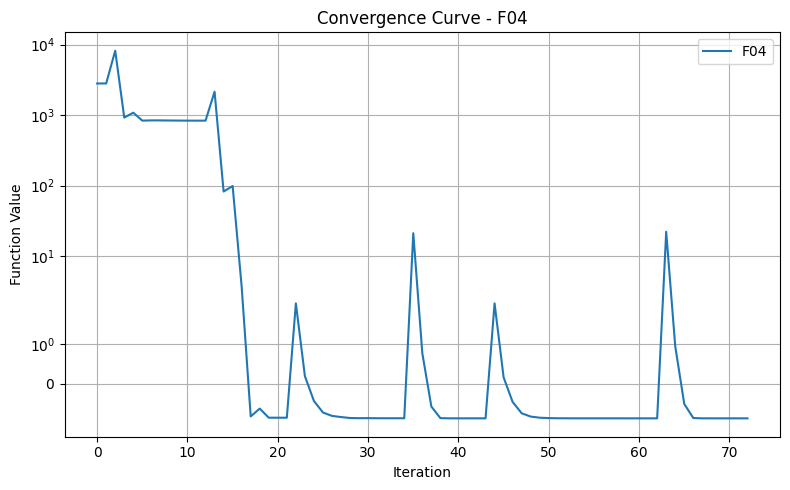

Running F05 (dim=2)...


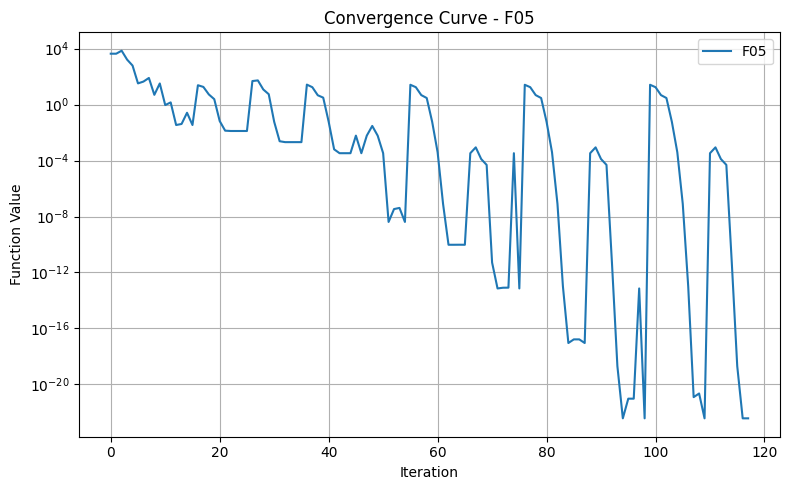

Running F06 (dim=2)...


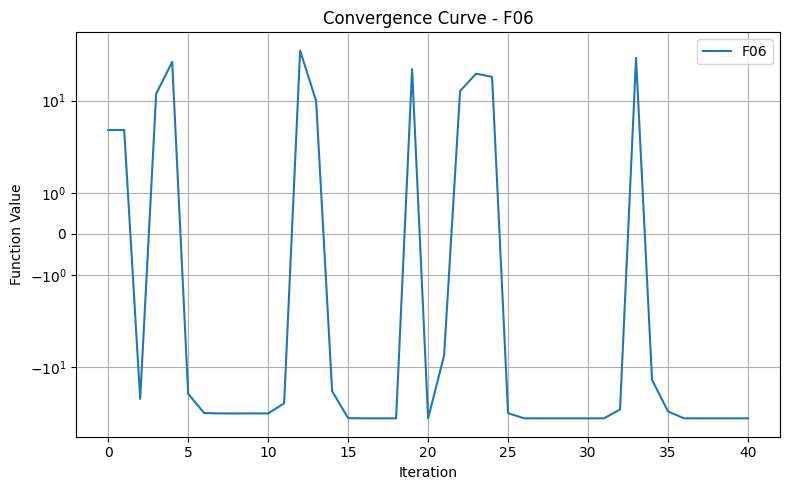

Running F07 (dim=2)...


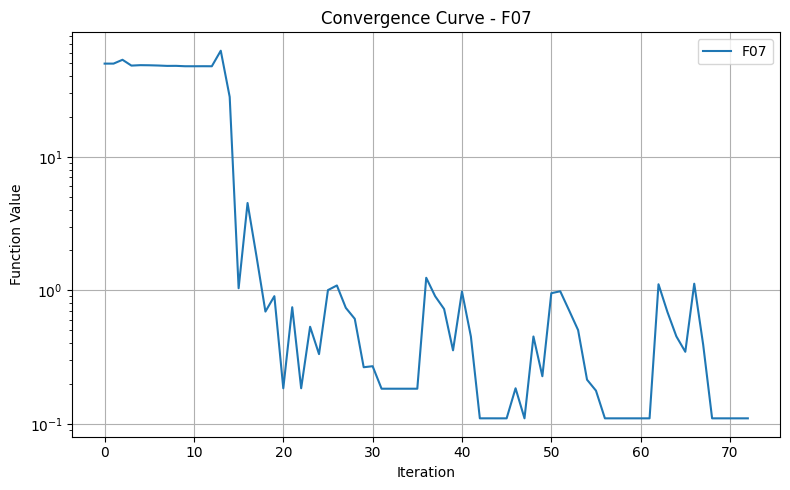

Running F08 (dim=2)...


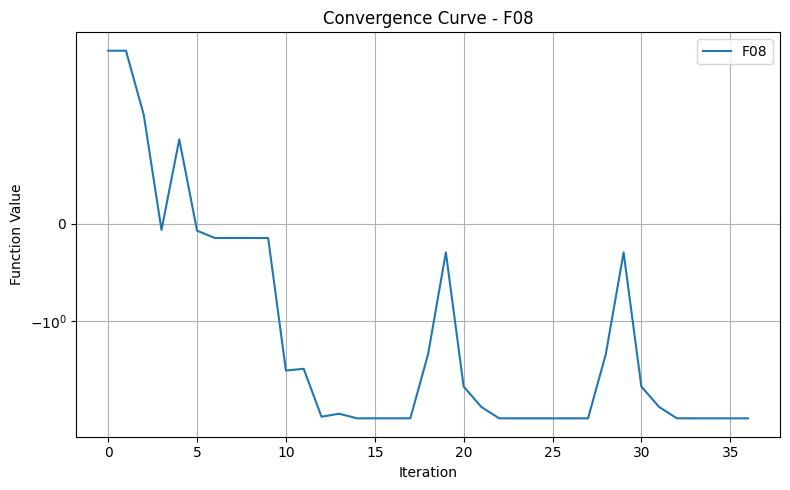

Running F09 (dim=2)...


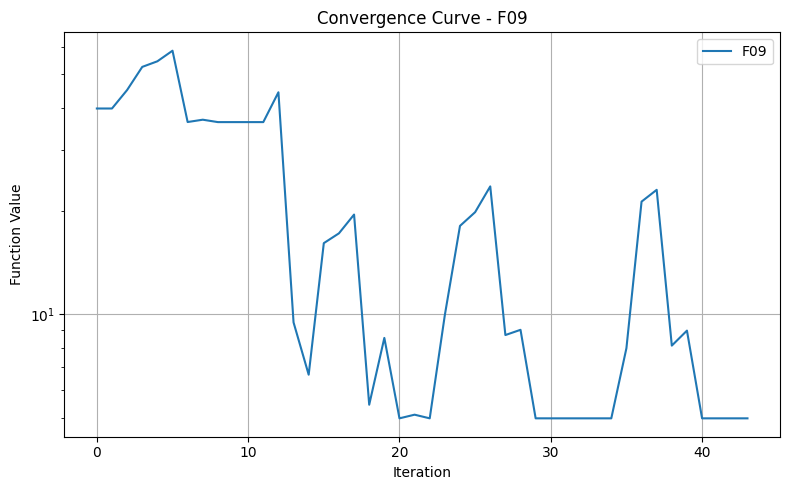

Running F10 (dim=3)...


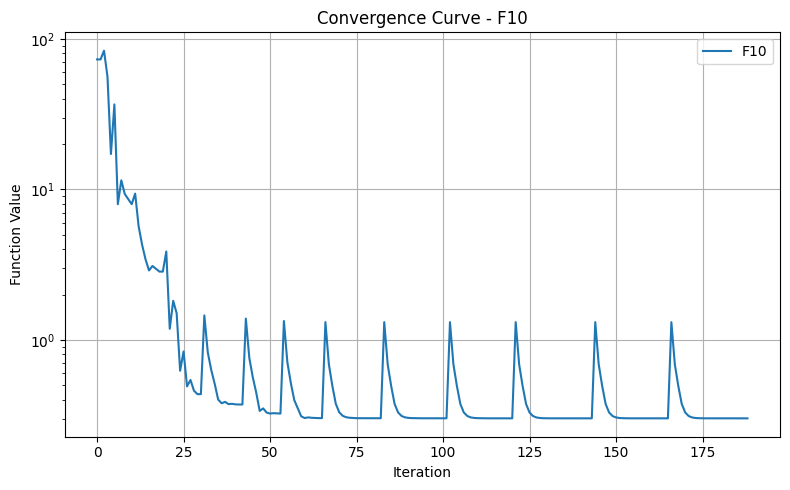

Running F11 (dim=2)...


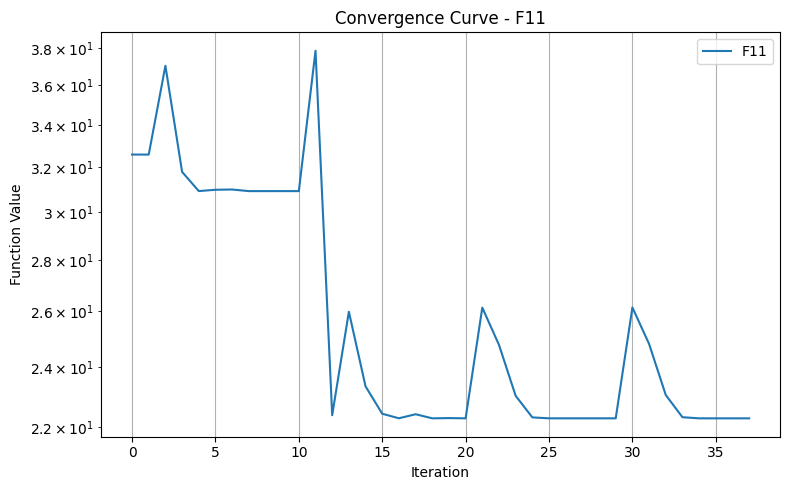

Running F12 (dim=5)...


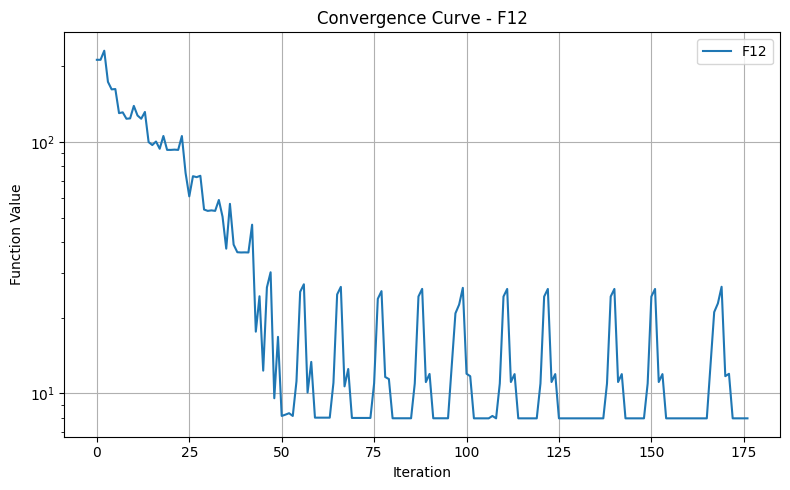


--- Benchmark Results ---
                   Best          Mean        Median         Worst  \
Function                                                            
F01        0.000000e+00  6.622614e-12  0.000000e+00  1.941274e-10   
F02        4.403957e-69  2.051481e-07  6.203920e-38  5.871291e-06   
F03       2.369195e-103  1.848782e-45  2.822935e-84  4.752188e-44   
F04       -8.898143e-01 -8.898142e-01 -8.898143e-01 -8.898138e-01   
F05        0.000000e+00  1.697690e-24  2.879342e-29  3.756461e-23   
F06       -1.867309e+02 -5.811785e+01 -3.423094e+01 -3.216150e+00   
F07        6.136837e-24  1.062112e-01  1.098737e-01  2.197473e-01   
F08       -2.000000e+00 -2.000000e+00 -2.000000e+00 -2.000000e+00   
F09        9.949591e-01  1.462578e+01  9.949560e+00  4.079297e+01   
F10        3.010000e-01  3.010000e-01  3.010000e-01  3.010001e-01   
F11        2.227924e+01  2.227924e+01  2.227924e+01  2.227924e+01   
F12        4.974795e+00  2.974314e+01  2.878360e+01  6.460172e+01   

      

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- Custom Benchmark Functions ---
def Five_Uneven_Peak_Trap(x):
    x = x[0]
    if x < 0 or x > 15:
        return 1e10
    if x < 2.5:
        return 80 * (2.5 - x)
    elif x < 5:
        return 64 * (x - 2.5)
    elif x < 7.5:
        return 64 * (7.5 - x)
    elif x < 12.5:
        return 28 * (x - 7.5)
    else:
        return 28 * (15 - x)

def Equal_Maxima(x):
    x = x[0]
    return np.sin(5 * np.pi * x) ** 6

def Uneven_Decreasing_Maxima(x):
    x = x[0]
    if x < 0:
        return 1e10
    return np.exp(-2 * np.log(2) * ((x - 0.08) / 0.854) ** 2) * np.sin(5 * np.pi * (x ** 0.75 - 0.05)) ** 6

def Six_Hump_Camel_Back(x):
    x1, x2 = x
    return (4 - 2.1 * x1**2 + x1**4 / 3) * x1**2 + x1 * x2 + (-4 + 4 * x2**2) * x2**2

def Himmelblau(x):
    x1, x2 = x
    return (x1**2 + x2 - 11) ** 2 + (x1 + x2**2 - 7) ** 2

def Shubert(x):
    x = np.asarray(x)
    result = 1
    for i in range(len(x)):
        s = 0
        for j in range(1, 6):
            s += j * np.cos((j + 1) * x[i] + j)
        result *= s
    return result

def Composition_Function_1(x):
    return np.sum((x - 1)**2) + np.sum(np.sin(3 * np.pi * x)**2)

def Vincent(x):
    x = np.asarray(x)
    if np.any(x <= 0):
        return 1e10
    return -np.sum(np.sin(10 * np.log(x)))

def Modified_Rastrigin_All_Global_Optima(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum((x - 0.1)**2 - 10 * np.cos(2 * np.pi * (x - 0.1)))

def Composition_Function_4(x):
    return np.sum(np.abs(x)) + np.prod(np.abs(x))

def Composition_Function_2(x):
    return np.sum((x + 1)**2) + np.sum(np.cos(2 * np.pi * (x + 1))) + 10 * len(x)

def Composition_Function_3(x):
    return np.sum(x**2 - 10 * np.cos(2 * np.pi * x)) + 10 * len(x)

benchmark_functions = {
    "F01": Five_Uneven_Peak_Trap,
    "F02": Equal_Maxima,
    "F03": Uneven_Decreasing_Maxima,
    "F04": Six_Hump_Camel_Back,
    "F05": Himmelblau,
    "F06": Shubert,
    "F07": Composition_Function_1,
    "F08": Vincent,
    "F09": Modified_Rastrigin_All_Global_Optima,
    "F10": Composition_Function_4,
    "F11": Composition_Function_2,
    "F12": Composition_Function_3
}

# --- Powell Optimizer with Bounds and Penalty ---
def powell(func, initial_guess, bounds=None):
    convergence_curve = []

    def wrapped_func(x):
        # Penalize out-of-bounds values
        if bounds is not None:
            for i, (lb, ub) in enumerate(bounds):
                if x[i] < lb or x[i] > ub:
                    return 1e10
        val = func(x)
        if not np.isfinite(val) or val > 1e10:
            return 1e10
        convergence_curve.append(val)
        return val

    result = minimize(
        fun=wrapped_func,
        x0=initial_guess,
        method='Powell',
        options={'maxiter': 1000, 'disp': False}
    )
    return result.x, result.fun, convergence_curve

# --- Run Single Benchmark ---
def run_benchmark(func, dim, runs=30, low=0.1, high=10):
    results = []
    convergence = None
    bounds = [(low, high)] * dim
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, val, curve = powell(func, x0, bounds=bounds)
            if np.isfinite(val):
                results.append(val)
                if convergence is None or (len(curve) < len(convergence)):
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    dim_dict = {
        "F01": 1, "F02": 1, "F03": 1,
        "F04": 2, "F05": 2, "F06": 2,
        "F07": 2, "F08": 2, "F09": 2,
        "F10": 3, "F11": 2, "F12": 5
    }
    for name, func in benchmark_functions.items():
        d = dim_dict.get(name, dim)
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All Benchmarks ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# --- Save to Excel ---
results.to_excel('Benchmark_Custom_Powell.xlsx')
print("\n✅ Results saved to Benchmark_Custom_Powell.xlsx")

Running F01 (dim=1)...


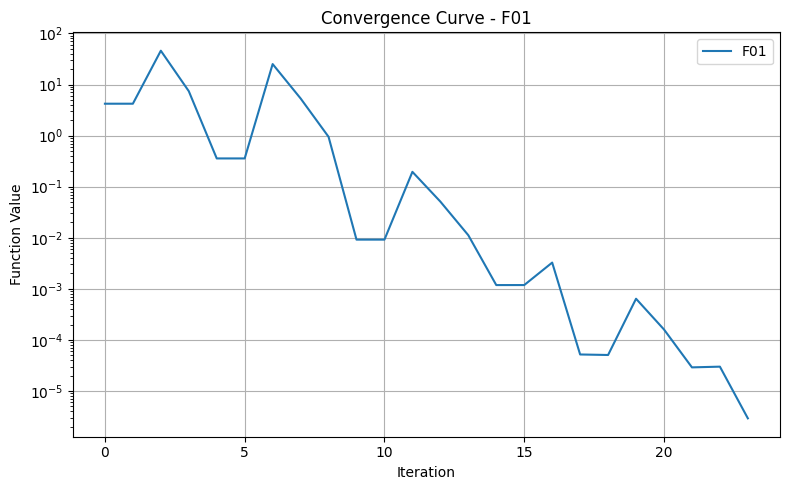

Running F02 (dim=1)...


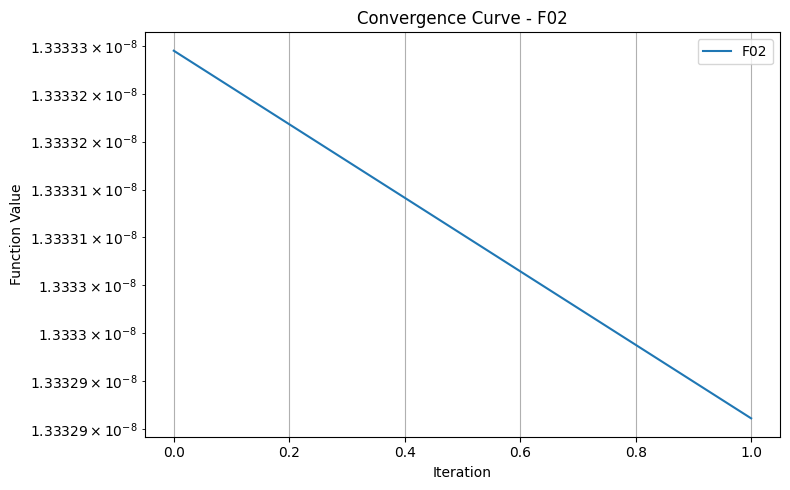

Running F03 (dim=1)...


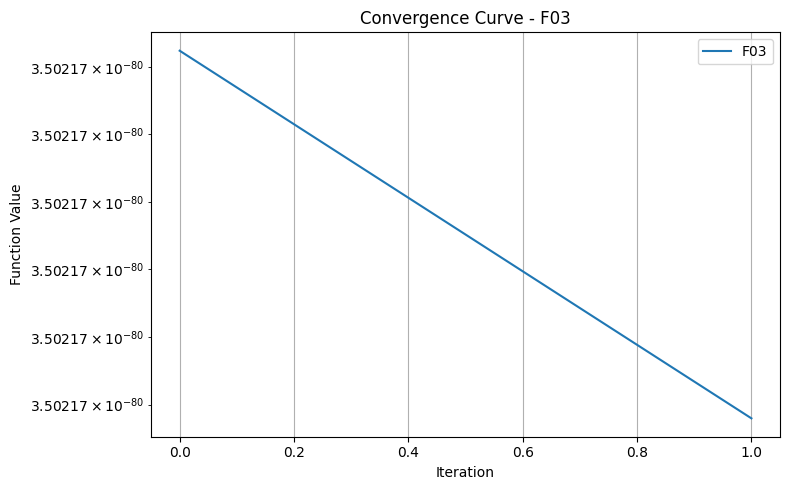

Running F04 (dim=2)...


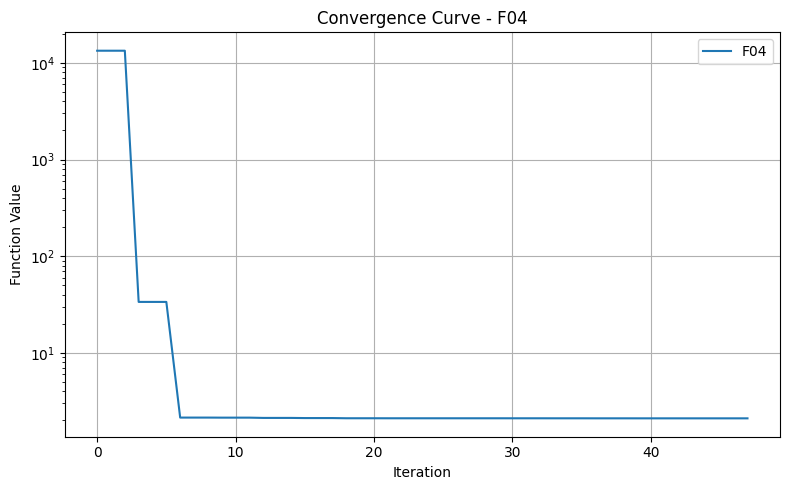

Running F05 (dim=2)...


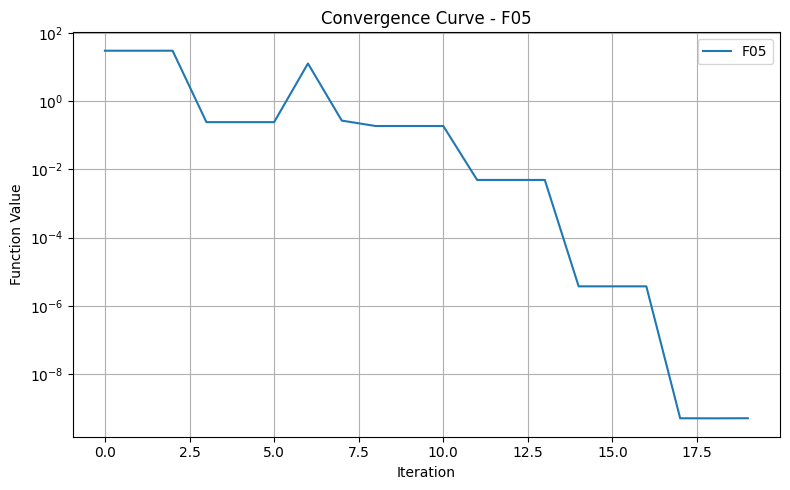

Running F06 (dim=2)...


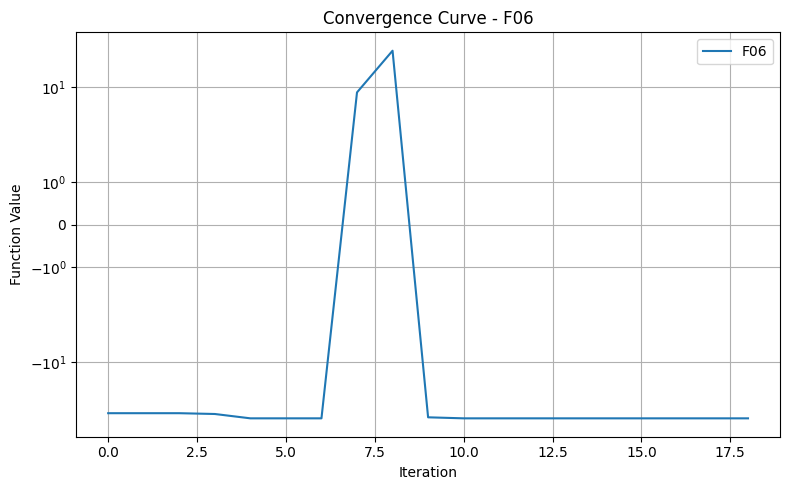

Running F07 (dim=2)...


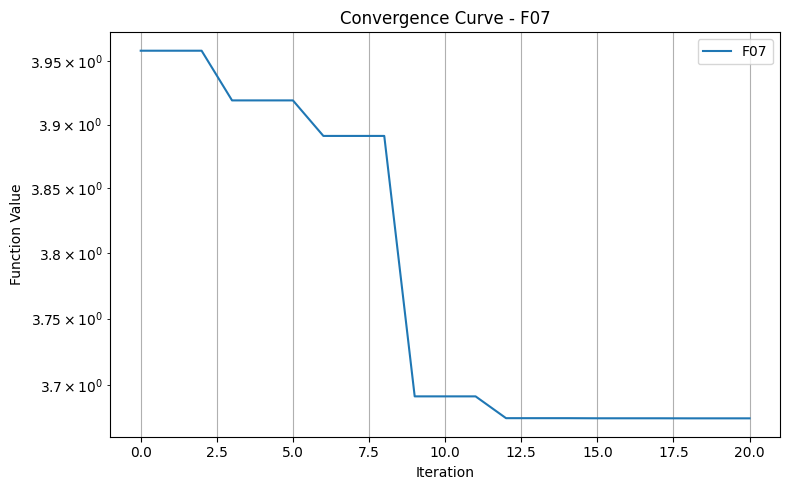

Running F08 (dim=2)...


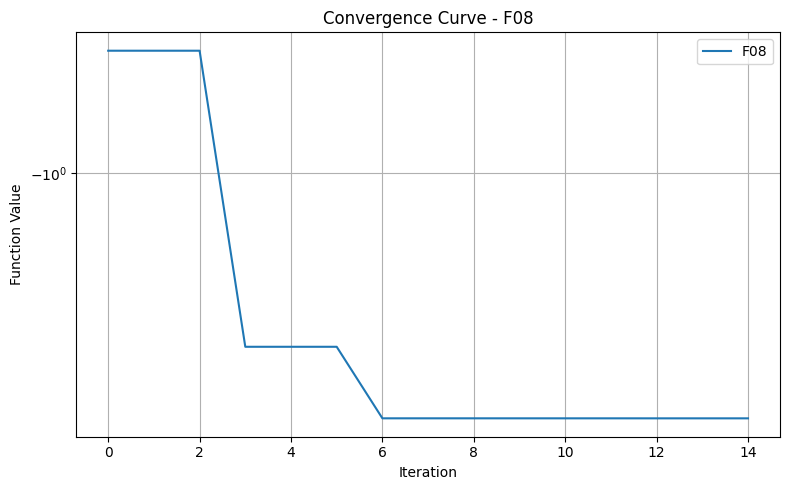

Running F09 (dim=2)...


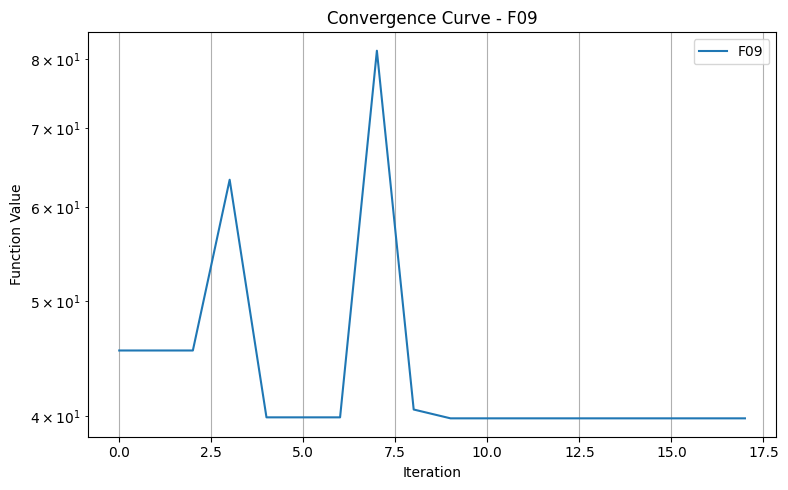

Running F10 (dim=3)...


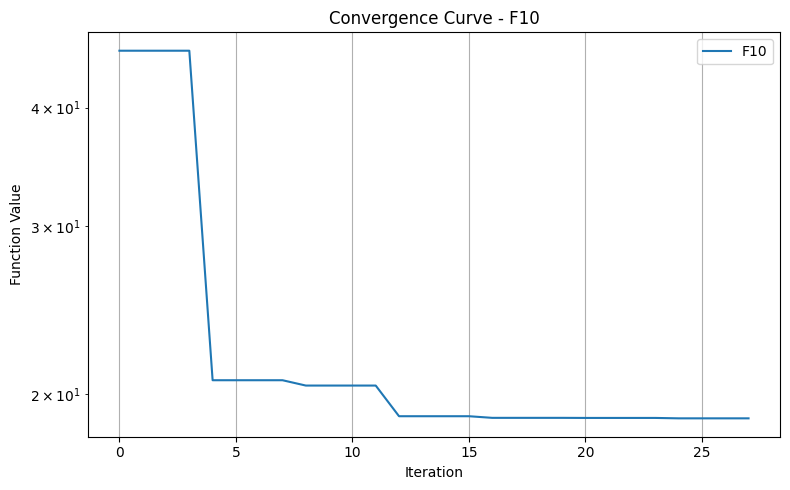

Running F11 (dim=2)...


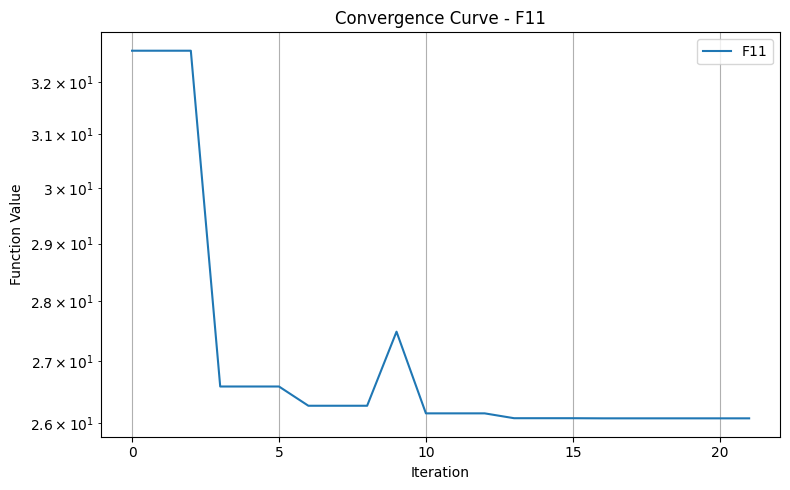

Running F12 (dim=5)...


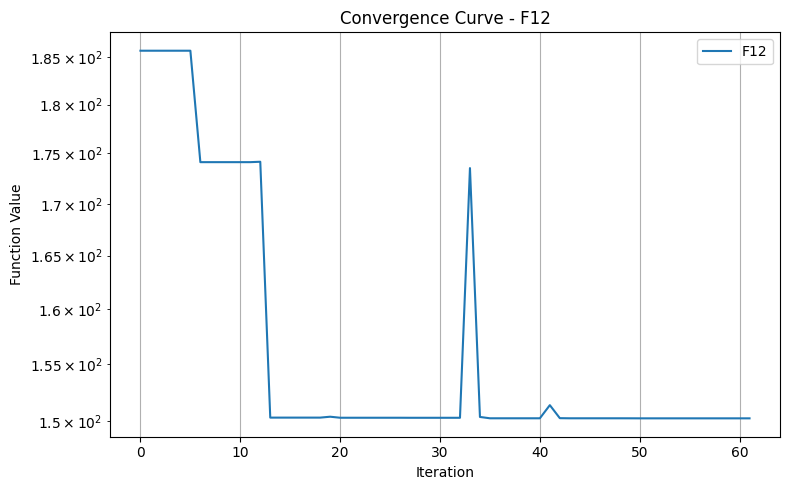


--- Benchmark Results ---
                  Best          Mean        Median         Worst           STD
Function                                                                      
F01       2.287178e-07  4.666395e-06  3.532195e-06  2.915117e-05  5.236946e-06
F02       5.029189e-17  1.227530e-06  4.640480e-07  1.233022e-05  2.753293e-06
F03       3.502171e-80  7.728196e-07  1.115037e-24  1.988021e-05  3.567571e-06
F04      -8.895612e-01  1.000000e+09  2.511842e+00  1.000000e+10  3.000000e+09
F05       4.996113e-10  1.333333e+09  7.232532e-08  1.000000e+10  3.399346e+09
F06      -1.867309e+02 -4.162497e+01 -3.177584e+01 -7.722749e+00  4.040375e+01
F07       7.063663e-09  6.666667e+08  6.096698e+00  1.000000e+10  2.494438e+09
F08      -2.000000e+00 -2.000000e+00 -2.000000e+00 -2.000000e+00  1.110602e-07
F09       7.714748e-01  4.212615e+01  2.487385e+01  1.293409e+02  3.837723e+01
F10       1.000000e+10  1.000000e+10  1.000000e+10  1.000000e+10  0.000000e+00
F11       2.227924e+01  1

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- Custom Benchmark Functions ---
def Five_Uneven_Peak_Trap(x):
    x = x[0]
    if x < 0 or x > 15:
        return 1e10
    if x < 2.5:
        return 80 * (2.5 - x)
    elif x < 5:
        return 64 * (x - 2.5)
    elif x < 7.5:
        return 64 * (7.5 - x)
    elif x < 12.5:
        return 28 * (x - 7.5)
    else:
        return 28 * (15 - x)

def Equal_Maxima(x):
    x = x[0]
    return np.sin(5 * np.pi * x) ** 6

def Uneven_Decreasing_Maxima(x):
    x = x[0]
    if x < 0:
        return 1e10
    return np.exp(-2 * np.log(2) * ((x - 0.08) / 0.854) ** 2) * np.sin(5 * np.pi * (x ** 0.75 - 0.05)) ** 6

def Six_Hump_Camel_Back(x):
    x1, x2 = x
    return (4 - 2.1 * x1**2 + x1**4 / 3) * x1**2 + x1 * x2 + (-4 + 4 * x2**2) * x2**2

def Himmelblau(x):
    x1, x2 = x
    return (x1**2 + x2 - 11) ** 2 + (x1 + x2**2 - 7) ** 2

def Shubert(x):
    x = np.asarray(x)
    result = 1
    for i in range(len(x)):
        s = 0
        for j in range(1, 6):
            s += j * np.cos((j + 1) * x[i] + j)
        result *= s
    return result

def Composition_Function_1(x):
    return np.sum((x - 1)**2) + np.sum(np.sin(3 * np.pi * x)**2)

def Vincent(x):
    x = np.asarray(x)
    if np.any(x <= 0):
        return 1e10
    return -np.sum(np.sin(10 * np.log(x)))

def Modified_Rastrigin_All_Global_Optima(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum((x - 0.1)**2 - 10 * np.cos(2 * np.pi * (x - 0.1)))

def Composition_Function_4(x):
    return np.sum(np.abs(x)) + np.prod(np.abs(x))

def Composition_Function_2(x):
    return np.sum((x + 1)**2) + np.sum(np.cos(2 * np.pi * (x + 1))) + 10 * len(x)

def Composition_Function_3(x):
    return np.sum(x**2 - 10 * np.cos(2 * np.pi * x)) + 10 * len(x)

benchmark_functions = {
    "F01": Five_Uneven_Peak_Trap,
    "F02": Equal_Maxima,
    "F03": Uneven_Decreasing_Maxima,
    "F04": Six_Hump_Camel_Back,
    "F05": Himmelblau,
    "F06": Shubert,
    "F07": Composition_Function_1,
    "F08": Vincent,
    "F09": Modified_Rastrigin_All_Global_Optima,
    "F10": Composition_Function_4,
    "F11": Composition_Function_2,
    "F12": Composition_Function_3
}

# --- SLSQP Optimizer with Bounds and Penalty ---
def slsqp(func, initial_guess, bounds=None):
    convergence_curve = []

    def wrapped_func(x):
        # Penalize out-of-bounds values
        if bounds is not None:
            for i, (lb, ub) in enumerate(bounds):
                if x[i] < lb or x[i] > ub:
                    return 1e10
        val = func(x)
        if not np.isfinite(val) or val > 1e10:
            return 1e10
        convergence_curve.append(val)
        return val

    result = minimize(
        fun=wrapped_func,
        x0=initial_guess,
        method='SLSQP',
        options={'maxiter': 1000, 'disp': False}
    )
    return result.x, result.fun, convergence_curve

# --- Run Single Benchmark ---
def run_benchmark(func, dim, runs=30, low=0.1, high=10):
    results = []
    convergence = None
    bounds = [(low, high)] * dim
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, val, curve = slsqp(func, x0, bounds=bounds)
            if np.isfinite(val):
                results.append(val)
                if convergence is None or (len(curve) < len(convergence)):
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    dim_dict = {
        "F01": 1, "F02": 1, "F03": 1,
        "F04": 2, "F05": 2, "F06": 2,
        "F07": 2, "F08": 2, "F09": 2,
        "F10": 3, "F11": 2, "F12": 5
    }
    for name, func in benchmark_functions.items():
        d = dim_dict.get(name, dim)
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All Benchmarks ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# --- Save to Excel ---
results.to_excel('Benchmark_Custom_SLSQP.xlsx')
print("\n✅ Results saved to Benchmark_Custom_SLSQP.xlsx")

Running F01 (dim=1)...


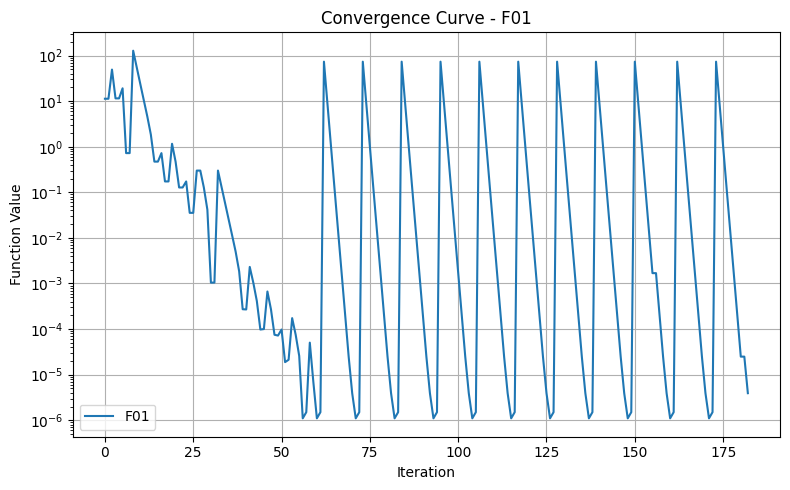

Running F02 (dim=1)...


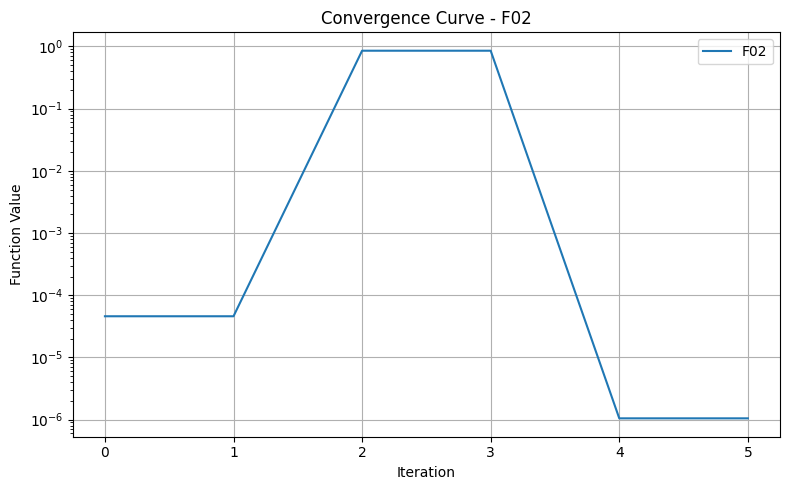

Running F03 (dim=1)...


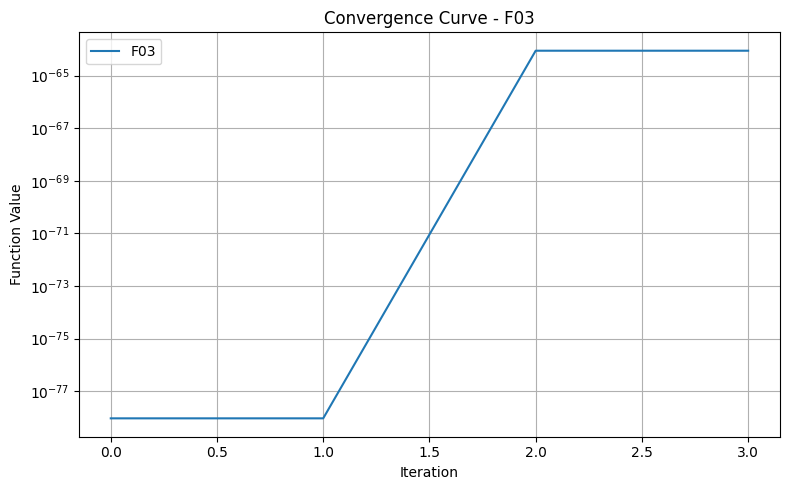

Running F04 (dim=2)...


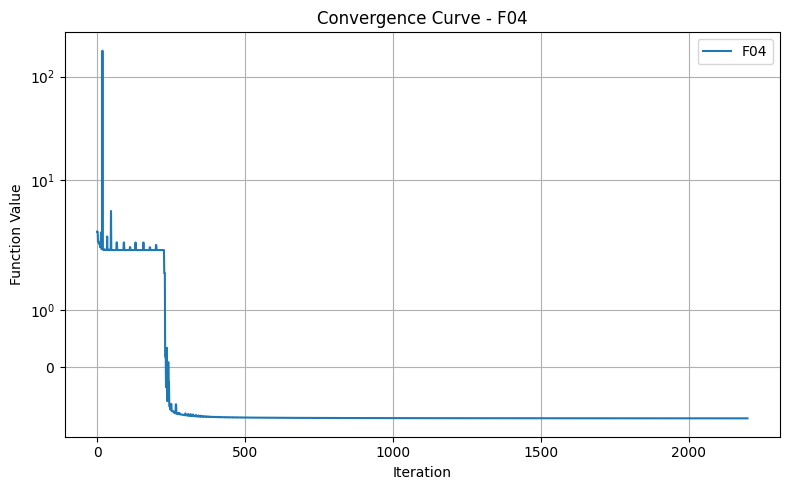

Running F05 (dim=2)...


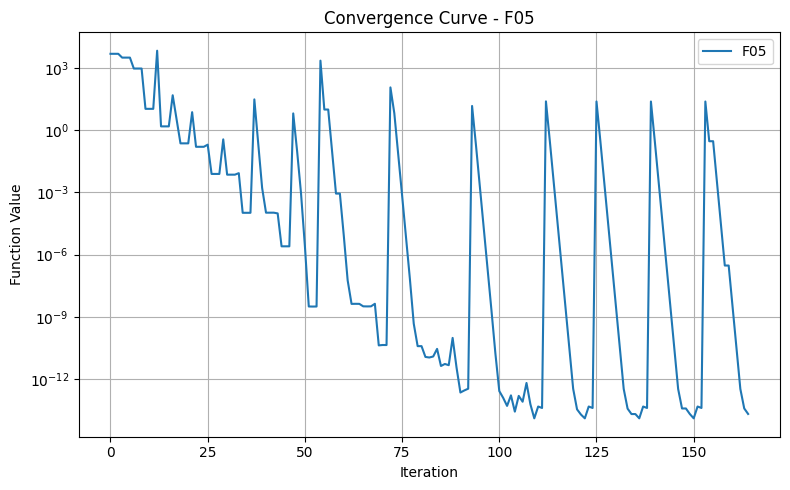

Running F06 (dim=2)...


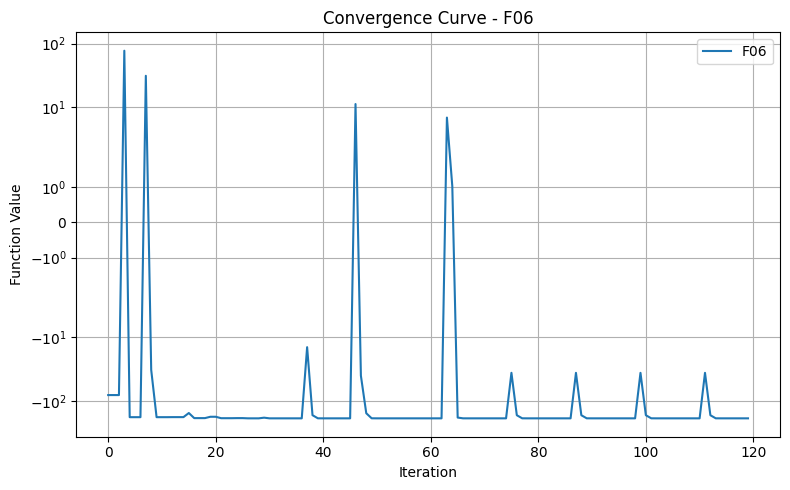

Running F07 (dim=2)...


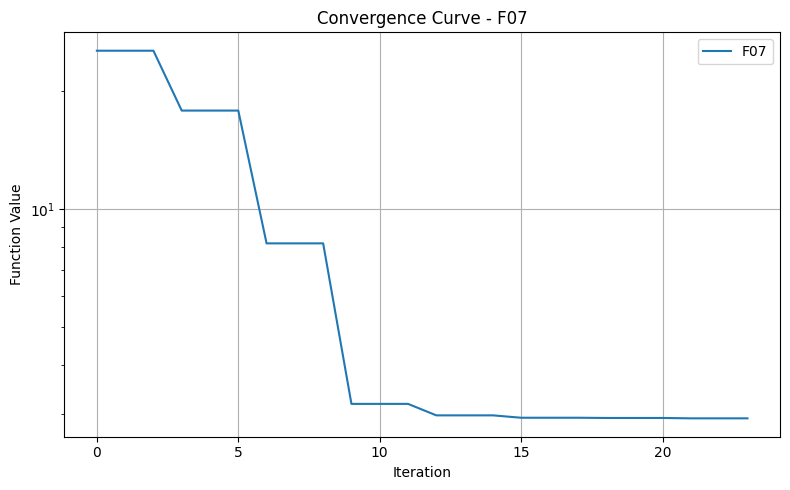

Running F08 (dim=2)...


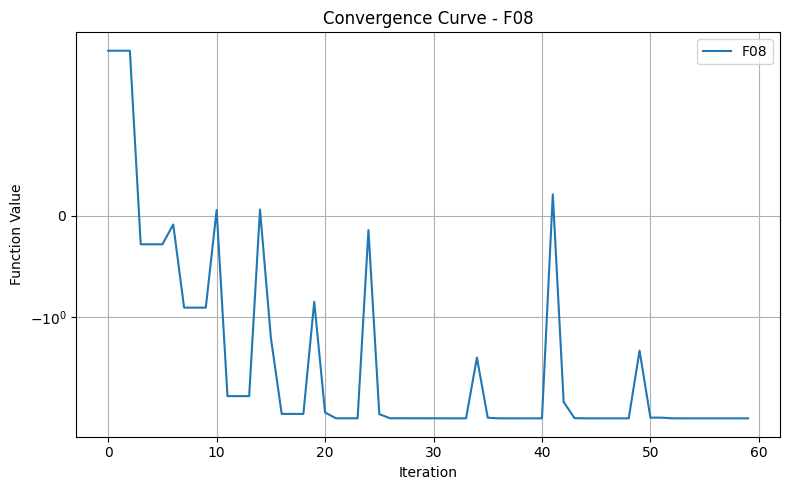

Running F09 (dim=2)...


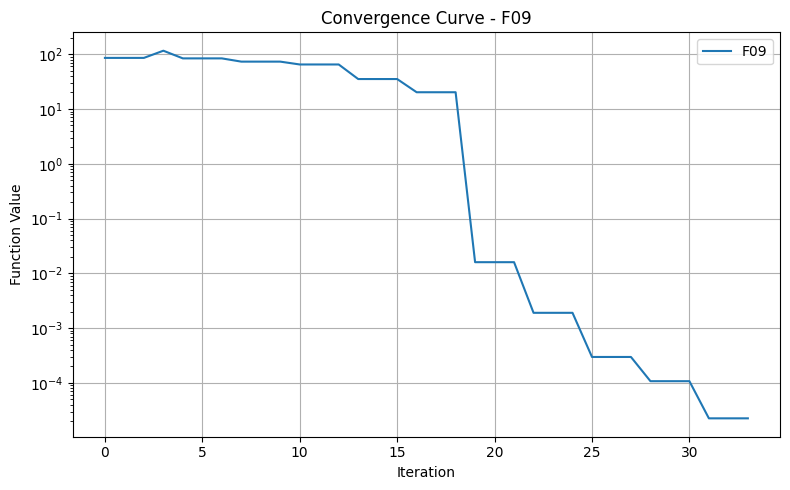

Running F10 (dim=3)...


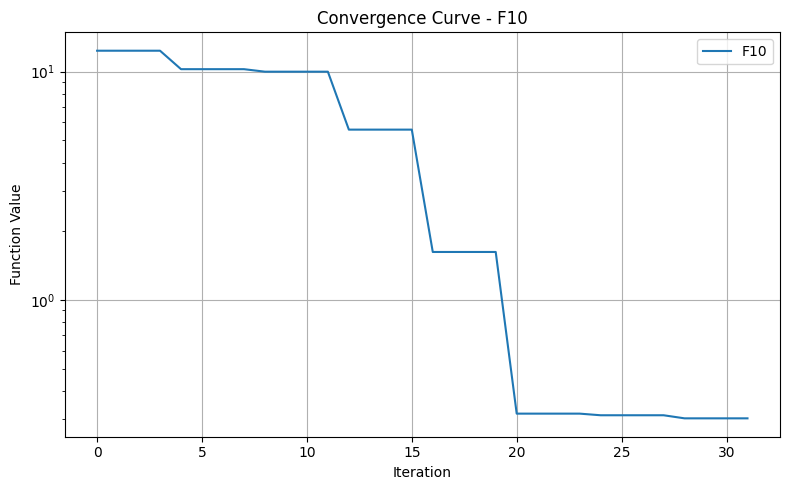

Running F11 (dim=2)...


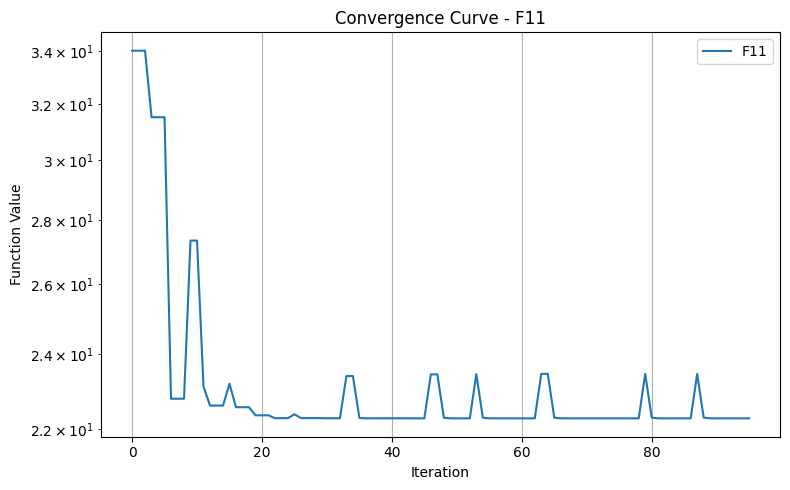

Running F12 (dim=5)...


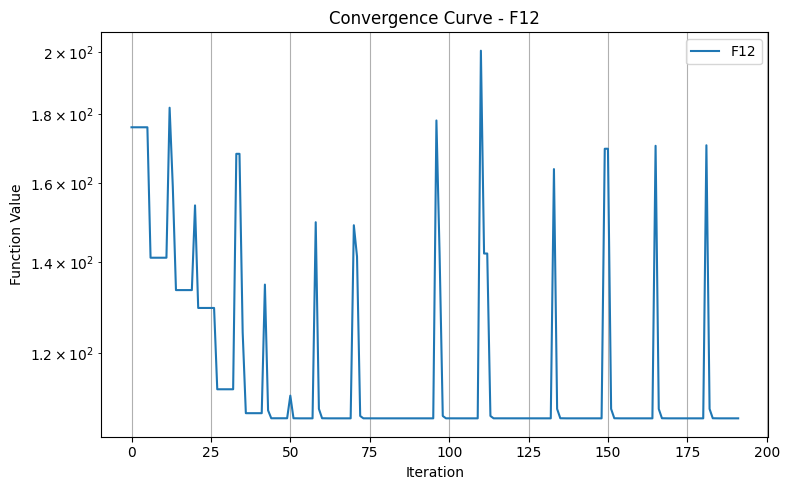


--- Benchmark Results ---
                  Best          Mean        Median         Worst           STD
Function                                                                      
F01       2.936275e-09  3.679093e-07  2.609104e-07  2.111860e-06  4.321794e-07
F02       1.957671e-18  3.664025e-08  1.796770e-13  1.048246e-06  1.880276e-07
F03       8.793688e-65  6.712798e-12  3.119377e-24  1.442171e-10  2.751329e-11
F04      -8.882029e-01 -7.853653e-01 -8.877937e-01  2.181559e+00  5.509442e-01
F05       1.859983e-18  9.541710e-15  1.052402e-14  1.890911e-14  5.558545e-15
F06      -1.867309e+02 -3.209390e+01 -1.319971e+01 -7.722749e+00  4.111283e+01
F07       3.385990e-16  1.948856e+00  1.511732e+00  8.536534e+00  2.028035e+00
F08      -2.000000e+00 -1.995293e+00 -2.000000e+00 -1.858784e+00  2.534899e-02
F09       7.167137e-07  4.630740e+01  2.240157e+01  1.637623e+02  5.070876e+01
F10       3.011083e-01  1.006638e+00  3.014800e-01  2.143870e+01  3.794139e+00
F11       2.227924e+01  2

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- Custom Benchmark Functions ---
def Five_Uneven_Peak_Trap(x):
    x = x[0]
    if x < 0 or x > 15:
        return 1e10
    if x < 2.5:
        return 80 * (2.5 - x)
    elif x < 5:
        return 64 * (x - 2.5)
    elif x < 7.5:
        return 64 * (7.5 - x)
    elif x < 12.5:
        return 28 * (x - 7.5)
    else:
        return 28 * (15 - x)

def Equal_Maxima(x):
    x = x[0]
    return np.sin(5 * np.pi * x) ** 6

def Uneven_Decreasing_Maxima(x):
    x = x[0]
    if x < 0:
        return 1e10
    return np.exp(-2 * np.log(2) * ((x - 0.08) / 0.854) ** 2) * np.sin(5 * np.pi * (x ** 0.75 - 0.05)) ** 6

def Six_Hump_Camel_Back(x):
    x1, x2 = x
    return (4 - 2.1 * x1**2 + x1**4 / 3) * x1**2 + x1 * x2 + (-4 + 4 * x2**2) * x2**2

def Himmelblau(x):
    x1, x2 = x
    return (x1**2 + x2 - 11) ** 2 + (x1 + x2**2 - 7) ** 2

def Shubert(x):
    x = np.asarray(x)
    result = 1
    for i in range(len(x)):
        s = 0
        for j in range(1, 6):
            s += j * np.cos((j + 1) * x[i] + j)
        result *= s
    return result

def Composition_Function_1(x):
    return np.sum((x - 1)**2) + np.sum(np.sin(3 * np.pi * x)**2)

def Vincent(x):
    x = np.asarray(x)
    if np.any(x <= 0):
        return 1e10
    return -np.sum(np.sin(10 * np.log(x)))

def Modified_Rastrigin_All_Global_Optima(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum((x - 0.1)**2 - 10 * np.cos(2 * np.pi * (x - 0.1)))

def Composition_Function_4(x):
    return np.sum(np.abs(x)) + np.prod(np.abs(x))

def Composition_Function_2(x):
    return np.sum((x + 1)**2) + np.sum(np.cos(2 * np.pi * (x + 1))) + 10 * len(x)

def Composition_Function_3(x):
    return np.sum(x**2 - 10 * np.cos(2 * np.pi * x)) + 10 * len(x)

benchmark_functions = {
    "F01": Five_Uneven_Peak_Trap,
    "F02": Equal_Maxima,
    "F03": Uneven_Decreasing_Maxima,
    "F04": Six_Hump_Camel_Back,
    "F05": Himmelblau,
    "F06": Shubert,
    "F07": Composition_Function_1,
    "F08": Vincent,
    "F09": Modified_Rastrigin_All_Global_Optima,
    "F10": Composition_Function_4,
    "F11": Composition_Function_2,
    "F12": Composition_Function_3
}

# --- trust-constr Optimizer with Bounds and Fixed Hessian ---
def tc(func, initial_guess, bounds=None):
    convergence_curve = []

    def wrapped_func(x):
        if bounds is not None:
            for i, (lb, ub) in enumerate(bounds):
                if x[i] < lb or x[i] > ub:
                    return 1e10
        val = func(x)
        if not np.isfinite(val) or val > 1e10:
            return 1e10
        convergence_curve.append(val)
        return val

    result = minimize(
        fun=wrapped_func,
        x0=initial_guess,
        method='trust-constr',
        jac='2-point',
        hess=lambda x: np.zeros((len(x), len(x))),  # Fixed zero Hessian
        bounds=bounds,
        options={'maxiter': 1000, 'disp': False}
    )
    return result.x, result.fun, convergence_curve

# --- Run Single Benchmark ---
def run_benchmark(func, dim, runs=30, low=0.1, high=10):
    results = []
    convergence = None
    bounds = [(low, high)] * dim
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, val, curve = tc(func, x0, bounds=bounds)
            if np.isfinite(val):
                results.append(val)
                if convergence is None or (len(curve) < len(convergence)):
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    dim_dict = {
        "F01": 1, "F02": 1, "F03": 1,
        "F04": 2, "F05": 2, "F06": 2,
        "F07": 2, "F08": 2, "F09": 2,
        "F10": 3, "F11": 2, "F12": 5
    }
    for name, func in benchmark_functions.items():
        d = dim_dict.get(name, dim)
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All Benchmarks ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# --- Save to Excel ---
results.to_excel('Benchmark_Custom_trust-constr.xlsx')
print("\n✅ Results saved to Benchmark_Custom_trust-constr.xlsx")

Running F01 (dim=1)...


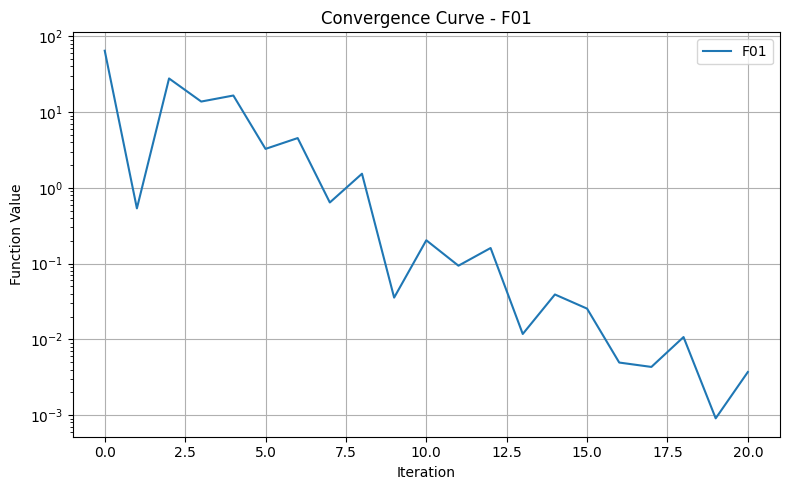

Running F02 (dim=1)...


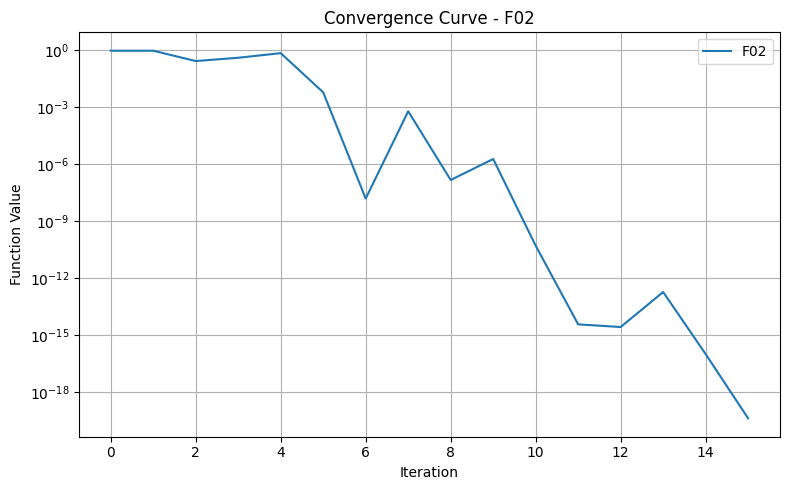

Running F03 (dim=1)...


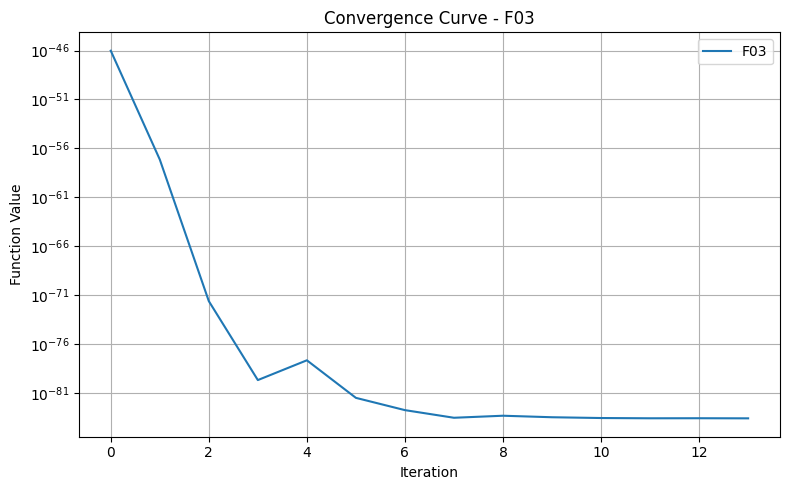

Running F04 (dim=2)...


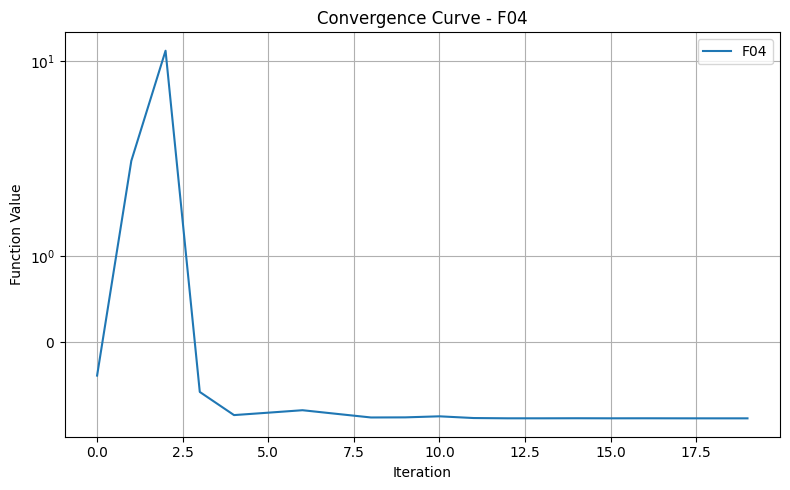

Running F05 (dim=2)...


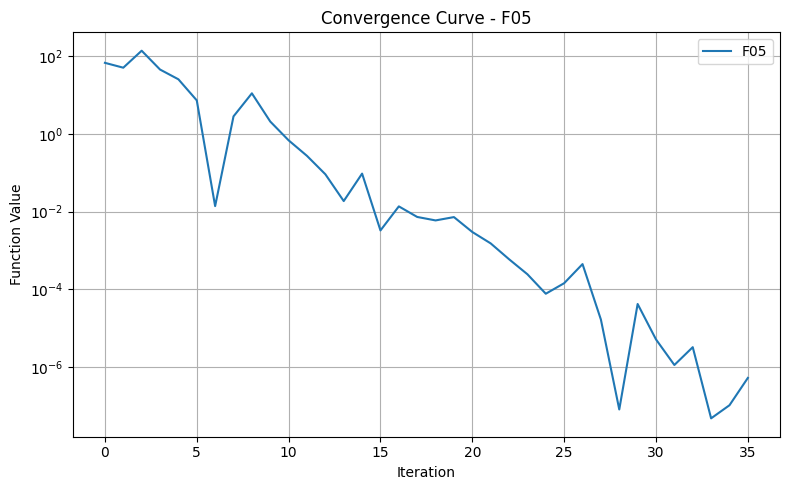

Running F06 (dim=2)...


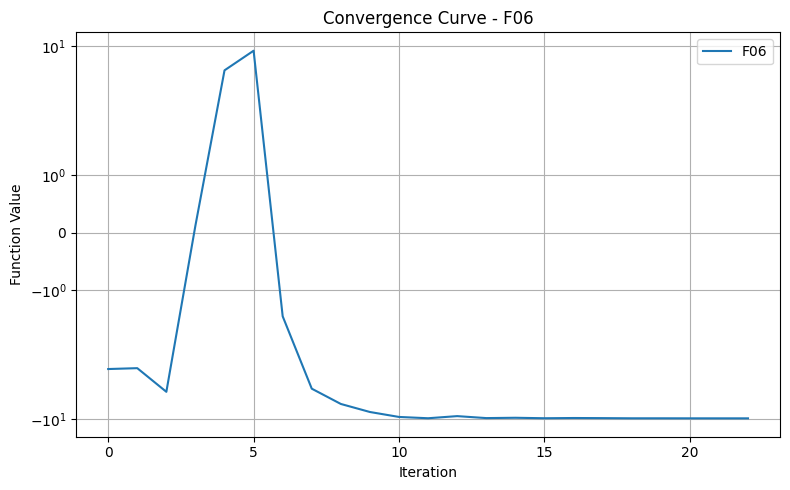

Running F07 (dim=2)...


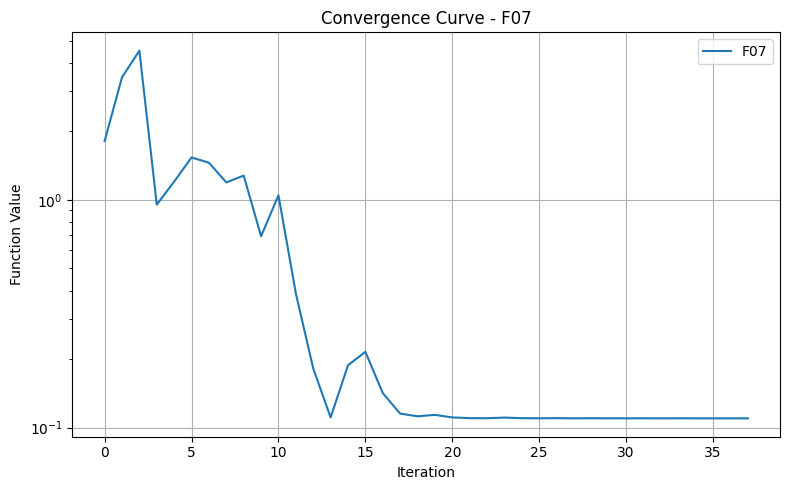

Running F08 (dim=2)...


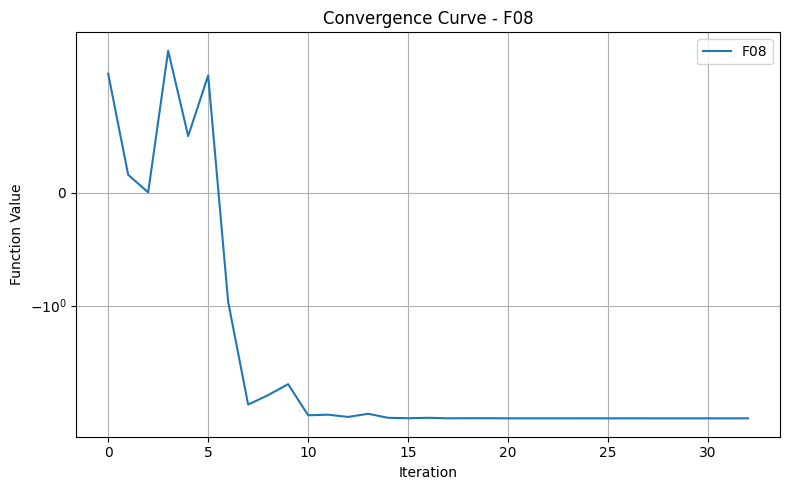

Running F09 (dim=2)...


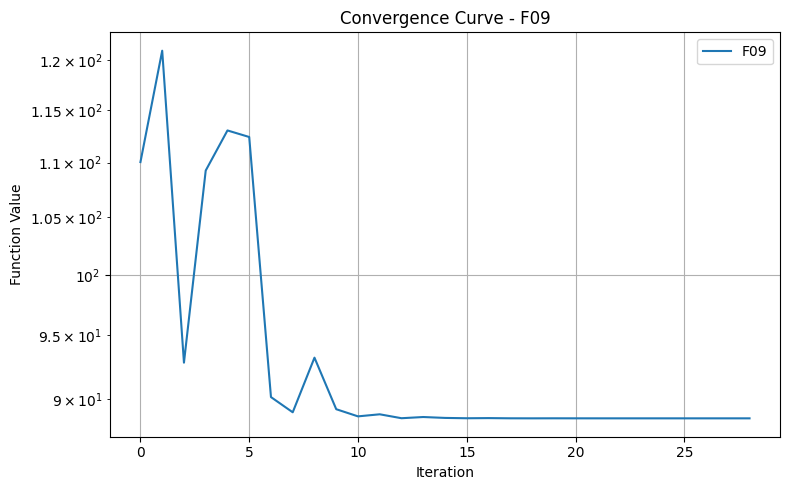

Running F10 (dim=3)...


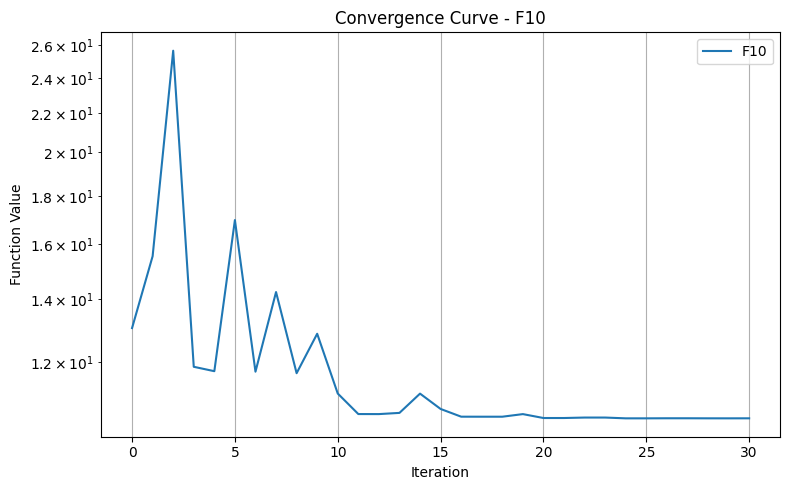

Running F11 (dim=2)...


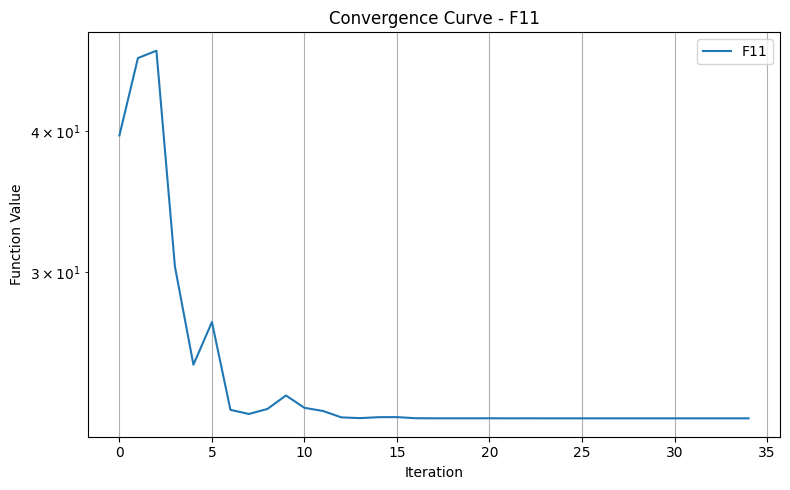

Running F12 (dim=5)...


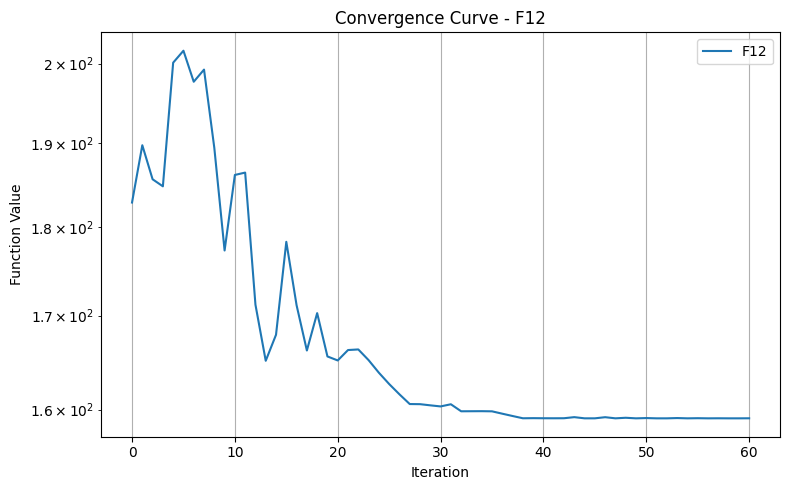


--- Benchmark Results ---
                   Best          Mean        Median         Worst  \
Function                                                            
F01        2.547140e-03  5.878254e-03  5.677888e-03  9.430677e-03   
F02        1.454064e-27  1.122723e-17  8.168909e-20  9.918321e-17   
F03       5.551864e-104  2.333333e+09  4.392579e-53  1.000000e+10   
F04       -8.851540e-01  2.666667e+09  2.104250e+00  1.000000e+10   
F05        2.867436e-08  3.333333e+08  3.405819e-07  1.000000e+10   
F06       -1.867309e+02  1.000000e+09 -1.921076e+01  1.000000e+10   
F07        1.244450e-07  6.115454e-01  1.648117e-01  8.018509e+00   
F08       -2.000000e+00 -2.000000e+00 -2.000000e+00 -1.999992e+00   
F09        4.974791e+00  3.333334e+08  5.671177e+01  1.000000e+10   
F10        1.378265e+00  4.666667e+09  2.010000e+01  1.000000e+10   
F11        2.227924e+01  2.493384e+01  2.607153e+01  2.607153e+01   
F12        6.367684e+01  1.458184e+02  1.373012e+02  3.153924e+02   

      

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- Custom Benchmark Functions ---
def Five_Uneven_Peak_Trap(x):
    x = x[0]
    if x < 0 or x > 15:
        return 1e10
    if x < 2.5:
        return 80 * (2.5 - x)
    elif x < 5:
        return 64 * (x - 2.5)
    elif x < 7.5:
        return 64 * (7.5 - x)
    elif x < 12.5:
        return 28 * (x - 7.5)
    else:
        return 28 * (15 - x)

def Equal_Maxima(x):
    x = x[0]
    return np.sin(5 * np.pi * x) ** 6

def Uneven_Decreasing_Maxima(x):
    x = x[0]
    if x < 0:
        return 1e10
    return np.exp(-2 * np.log(2) * ((x - 0.08) / 0.854) ** 2) * np.sin(5 * np.pi * (x ** 0.75 - 0.05)) ** 6

def Six_Hump_Camel_Back(x):
    x1, x2 = x
    return (4 - 2.1 * x1**2 + x1**4 / 3) * x1**2 + x1 * x2 + (-4 + 4 * x2**2) * x2**2

def Himmelblau(x):
    x1, x2 = x
    return (x1**2 + x2 - 11) ** 2 + (x1 + x2**2 - 7) ** 2

def Shubert(x):
    x = np.asarray(x)
    result = 1
    for i in range(len(x)):
        s = 0
        for j in range(1, 6):
            s += j * np.cos((j + 1) * x[i] + j)
        result *= s
    return result

def Composition_Function_1(x):
    return np.sum((x - 1)**2) + np.sum(np.sin(3 * np.pi * x)**2)

def Vincent(x):
    x = np.asarray(x)
    if np.any(x <= 0):
        return 1e10
    return -np.sum(np.sin(10 * np.log(x)))

def Modified_Rastrigin_All_Global_Optima(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum((x - 0.1)**2 - 10 * np.cos(2 * np.pi * (x - 0.1)))

def Composition_Function_4(x):
    return np.sum(np.abs(x)) + np.prod(np.abs(x))

def Composition_Function_2(x):
    return np.sum((x + 1)**2) + np.sum(np.cos(2 * np.pi * (x + 1))) + 10 * len(x)

def Composition_Function_3(x):
    return np.sum(x**2 - 10 * np.cos(2 * np.pi * x)) + 10 * len(x)

benchmark_functions = {
    "F01": Five_Uneven_Peak_Trap,
    "F02": Equal_Maxima,
    "F03": Uneven_Decreasing_Maxima,
    "F04": Six_Hump_Camel_Back,
    "F05": Himmelblau,
    "F06": Shubert,
    "F07": Composition_Function_1,
    "F08": Vincent,
    "F09": Modified_Rastrigin_All_Global_Optima,
    "F10": Composition_Function_4,
    "F11": Composition_Function_2,
    "F12": Composition_Function_3
}

# --- COBYLA Optimizer with Bounds and Penalty ---
def cobyla(func, initial_guess, bounds=None):
    convergence_curve = []

    def wrapped_func(x):
        # Penalize out-of-bounds values
        if bounds is not None:
            for i, (lb, ub) in enumerate(bounds):
                if x[i] < lb or x[i] > ub:
                    return 1e10
        val = func(x)
        if not np.isfinite(val) or val > 1e10:
            return 1e10
        convergence_curve.append(val)
        return val

    result = minimize(
        fun=wrapped_func,
        x0=initial_guess,
        method='COBYLA',
        options={'maxiter': 1000, 'disp': False}
    )
    return result.x, result.fun, convergence_curve

# --- Run Single Benchmark ---
def run_benchmark(func, dim, runs=30, low=0.1, high=10):
    results = []
    convergence = None
    bounds = [(low, high)] * dim
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, val, curve = cobyla(func, x0, bounds=bounds)
            if np.isfinite(val):
                results.append(val)
                if convergence is None or (len(curve) < len(convergence)):
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    dim_dict = {
        "F01": 1, "F02": 1, "F03": 1,
        "F04": 2, "F05": 2, "F06": 2,
        "F07": 2, "F08": 2, "F09": 2,
        "F10": 3, "F11": 2, "F12": 5
    }
    for name, func in benchmark_functions.items():
        d = dim_dict.get(name, dim)
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All Benchmarks ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# --- Save to Excel ---
results.to_excel('Benchmark_Custom_COBYLA.xlsx')
print("\n✅ Results saved to Benchmark_Custom_COBYLA.xlsx")

Running F01 (dim=1)...


/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_2654/3909057260.py:103: OptimizeWarning: Unknown solver options: maxiter
  result = minimize(


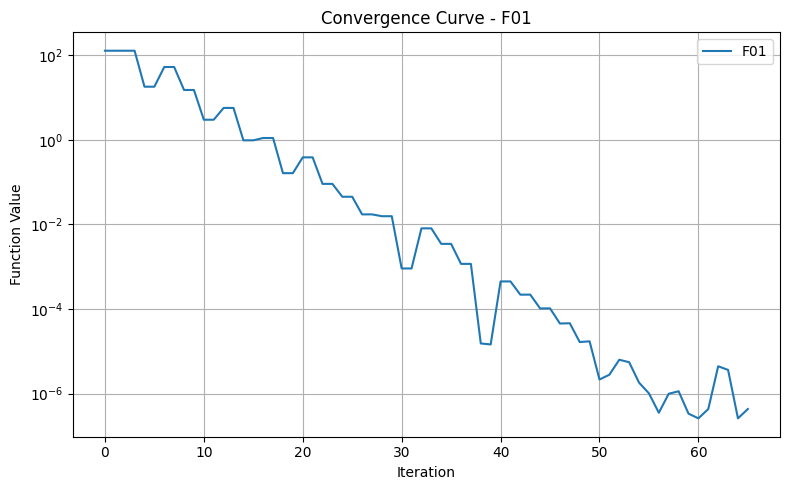

Running F02 (dim=1)...


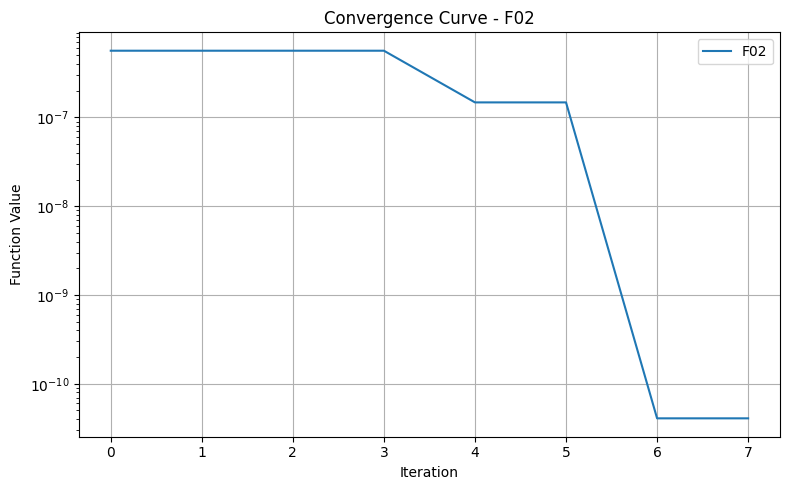

Running F03 (dim=1)...


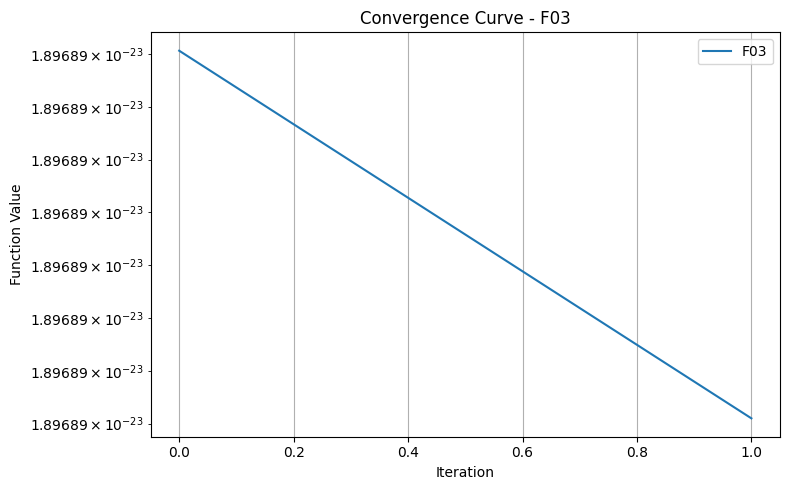

Running F04 (dim=2)...


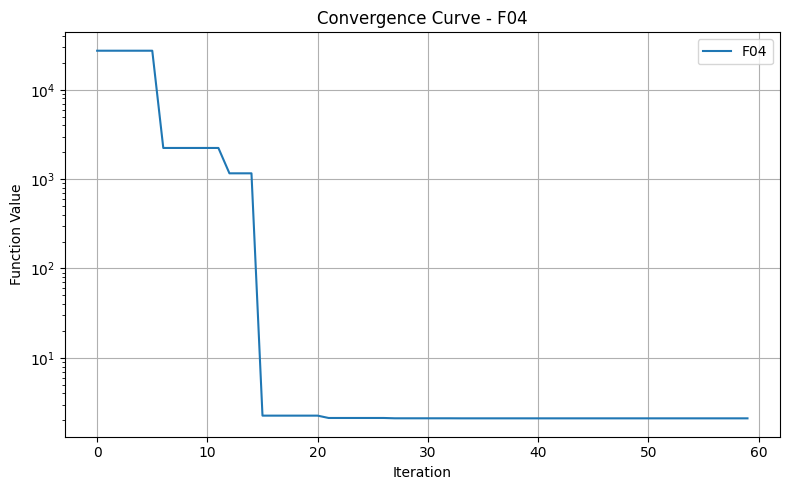

Running F05 (dim=2)...


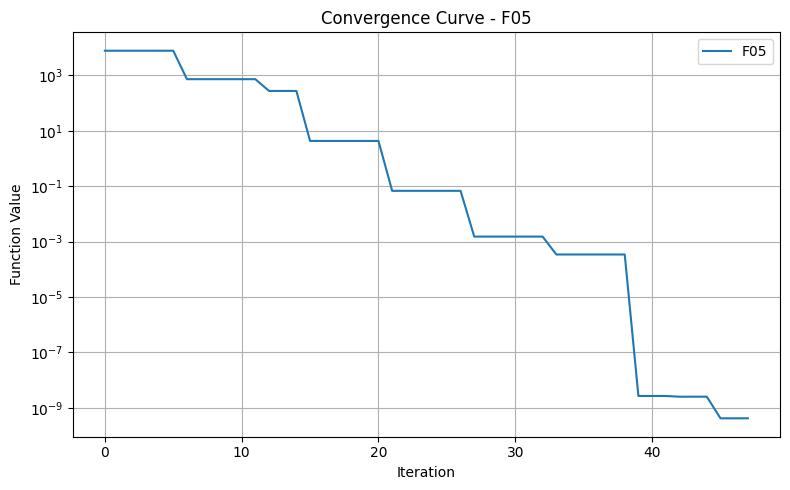

Running F06 (dim=2)...


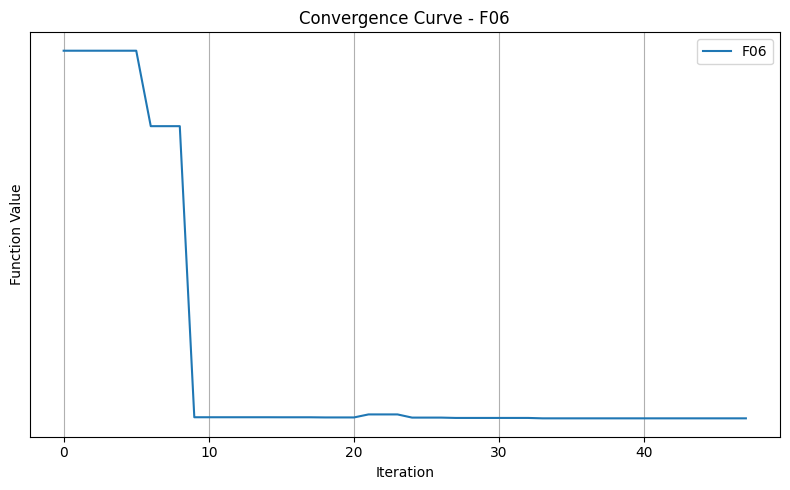

Running F07 (dim=2)...


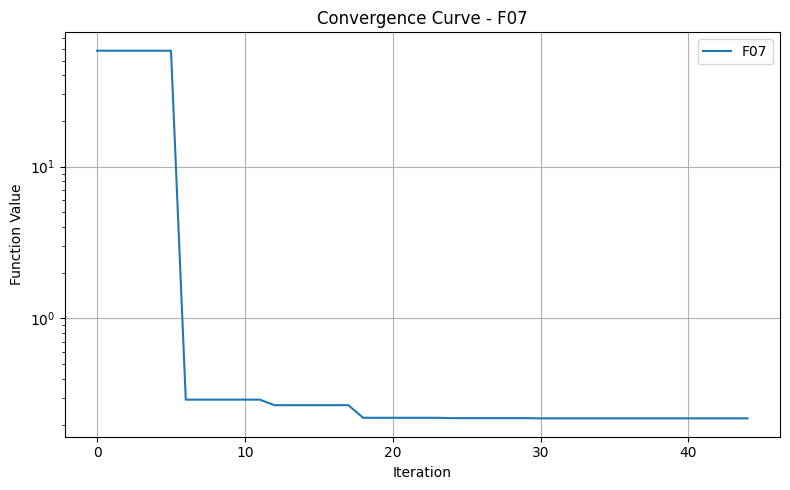

Running F08 (dim=2)...


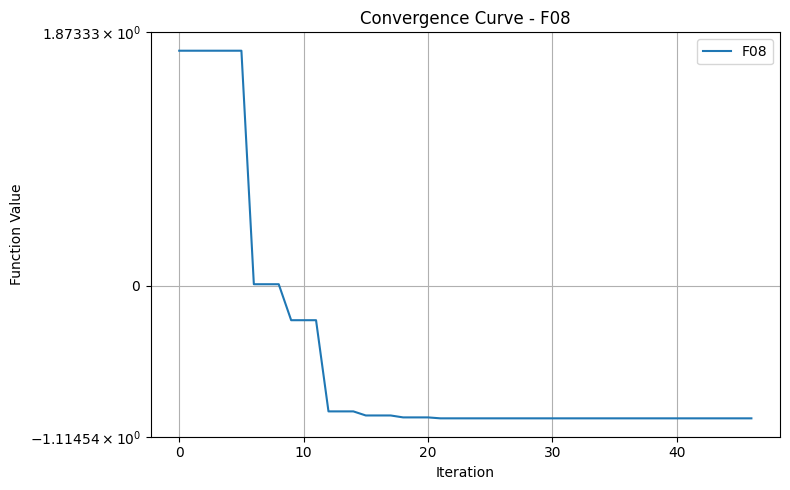

Running F09 (dim=2)...


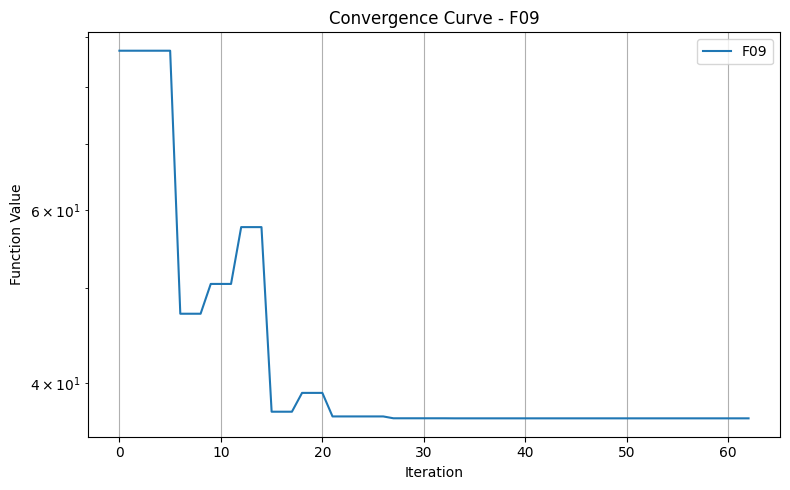

Running F10 (dim=3)...


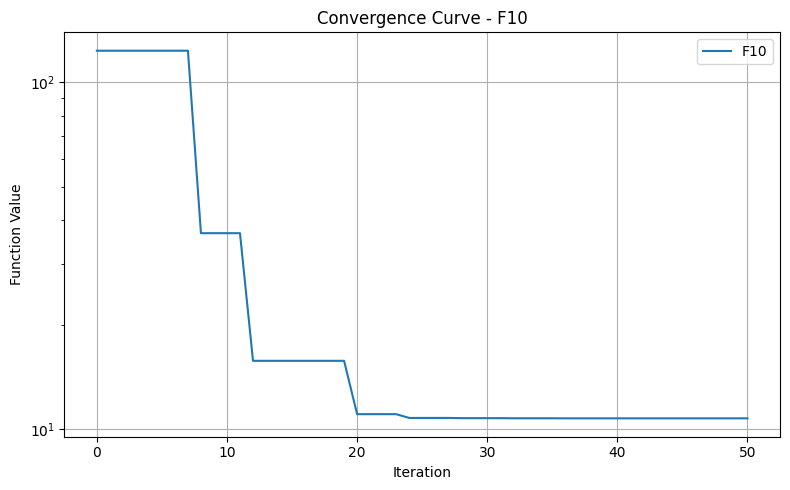

Running F11 (dim=2)...


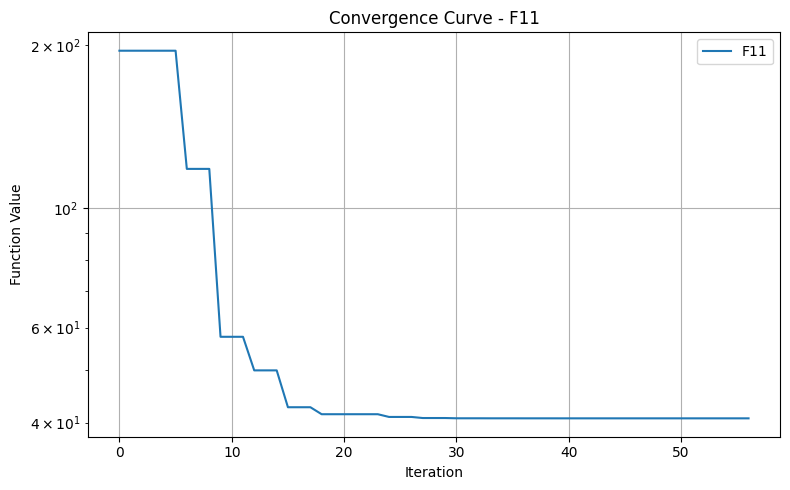

Running F12 (dim=5)...


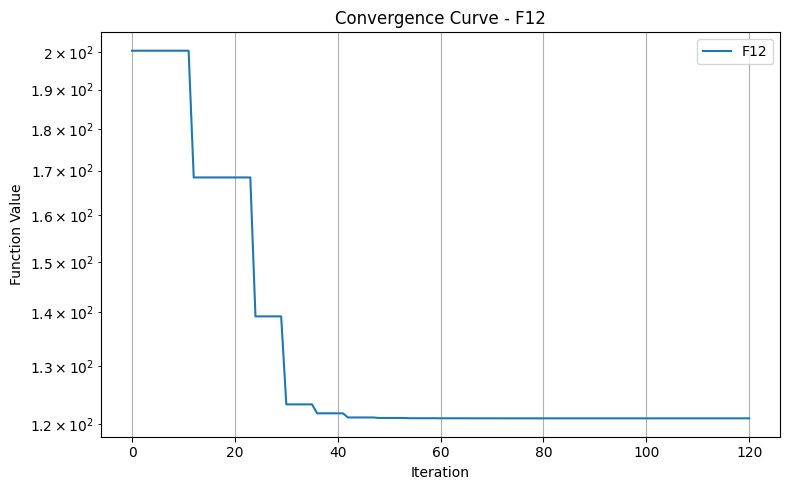


--- Benchmark Results ---
                  Best          Mean        Median         Worst           STD
Function                                                                      
F01       0.000000e+00  1.042795e-08  0.000000e+00  2.600970e-07  4.731801e-08
F02       2.731100e-15  5.390323e-12  2.167427e-13  4.078586e-11  1.017310e-11
F03       4.028469e-80  9.001373e-10  1.242821e-21  2.500196e-08  4.482703e-09
F04      -8.897817e-01  2.681899e+01 -1.052804e-01  7.624164e+02  1.367149e+02
F05       4.571103e-16  3.579880e-10  1.290369e-11  8.454592e-09  1.512345e-09
F06      -3.765607e+01 -1.391307e+01 -1.049744e+01 -7.722749e+00  8.097021e+00
F07       5.452334e-14  6.513590e+00  4.888408e+00  2.297756e+01  5.809661e+00
F08      -2.000000e+00 -1.965958e+00 -2.000000e+00 -9.787312e-01  1.833234e-01
F09       9.949591e-01  5.564640e+01  5.024461e+01  1.922563e+02  4.090775e+01
F10       5.026036e-01  4.919381e+00  2.908648e+00  1.644932e+01  3.915674e+00
F11       2.227924e+01  2

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- Custom Benchmark Functions ---
def Five_Uneven_Peak_Trap(x):
    x = x[0]
    if x < 0 or x > 15:
        return 1e10
    if x < 2.5:
        return 80 * (2.5 - x)
    elif x < 5:
        return 64 * (x - 2.5)
    elif x < 7.5:
        return 64 * (7.5 - x)
    elif x < 12.5:
        return 28 * (x - 7.5)
    else:
        return 28 * (15 - x)

def Equal_Maxima(x):
    x = x[0]
    return np.sin(5 * np.pi * x) ** 6

def Uneven_Decreasing_Maxima(x):
    x = x[0]
    if x < 0:
        return 1e10
    return np.exp(-2 * np.log(2) * ((x - 0.08) / 0.854) ** 2) * np.sin(5 * np.pi * (x ** 0.75 - 0.05)) ** 6

def Six_Hump_Camel_Back(x):
    x1, x2 = x
    return (4 - 2.1 * x1**2 + x1**4 / 3) * x1**2 + x1 * x2 + (-4 + 4 * x2**2) * x2**2

def Himmelblau(x):
    x1, x2 = x
    return (x1**2 + x2 - 11) ** 2 + (x1 + x2**2 - 7) ** 2

def Shubert(x):
    x = np.asarray(x)
    result = 1
    for i in range(len(x)):
        s = 0
        for j in range(1, 6):
            s += j * np.cos((j + 1) * x[i] + j)
        result *= s
    return result

def Composition_Function_1(x):
    return np.sum((x - 1)**2) + np.sum(np.sin(3 * np.pi * x)**2)

def Vincent(x):
    x = np.asarray(x)
    if np.any(x <= 0):
        return 1e10
    return -np.sum(np.sin(10 * np.log(x)))

def Modified_Rastrigin_All_Global_Optima(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum((x - 0.1)**2 - 10 * np.cos(2 * np.pi * (x - 0.1)))

def Composition_Function_4(x):
    return np.sum(np.abs(x)) + np.prod(np.abs(x))

def Composition_Function_2(x):
    return np.sum((x + 1)**2) + np.sum(np.cos(2 * np.pi * (x + 1))) + 10 * len(x)

def Composition_Function_3(x):
    return np.sum(x**2 - 10 * np.cos(2 * np.pi * x)) + 10 * len(x)

benchmark_functions = {
    "F01": Five_Uneven_Peak_Trap,
    "F02": Equal_Maxima,
    "F03": Uneven_Decreasing_Maxima,
    "F04": Six_Hump_Camel_Back,
    "F05": Himmelblau,
    "F06": Shubert,
    "F07": Composition_Function_1,
    "F08": Vincent,
    "F09": Modified_Rastrigin_All_Global_Optima,
    "F10": Composition_Function_4,
    "F11": Composition_Function_2,
    "F12": Composition_Function_3
}

# --- TNC Optimizer with Bounds and Penalty ---
def tnc(func, initial_guess, bounds=None):
    convergence_curve = []

    def wrapped_func(x):
        # Penalize out-of-bounds values
        if bounds is not None:
            for i, (lb, ub) in enumerate(bounds):
                if x[i] < lb or x[i] > ub:
                    return 1e10
        val = func(x)
        if not np.isfinite(val) or val > 1e10:
            return 1e10
        convergence_curve.append(val)
        return val

    result = minimize(
        fun=wrapped_func,
        x0=initial_guess,
        method='TNC',
        options={'maxiter': 1000, 'disp': False}
    )
    return result.x, result.fun, convergence_curve

# --- Run Single Benchmark ---
def run_benchmark(func, dim, runs=30, low=0.1, high=10):
    results = []
    convergence = None
    bounds = [(low, high)] * dim
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, val, curve = tnc(func, x0, bounds=bounds)
            if np.isfinite(val):
                results.append(val)
                if convergence is None or (len(curve) < len(convergence)):
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    dim_dict = {
        "F01": 1, "F02": 1, "F03": 1,
        "F04": 2, "F05": 2, "F06": 2,
        "F07": 2, "F08": 2, "F09": 2,
        "F10": 3, "F11": 2, "F12": 5
    }
    for name, func in benchmark_functions.items():
        d = dim_dict.get(name, dim)
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All Benchmarks ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# --- Save to Excel ---
results.to_excel('Benchmark_Custom_TNC.xlsx')
print("\n✅ Results saved to Benchmark_Custom_TNC.xlsx")

Running F01 (dim=1)...


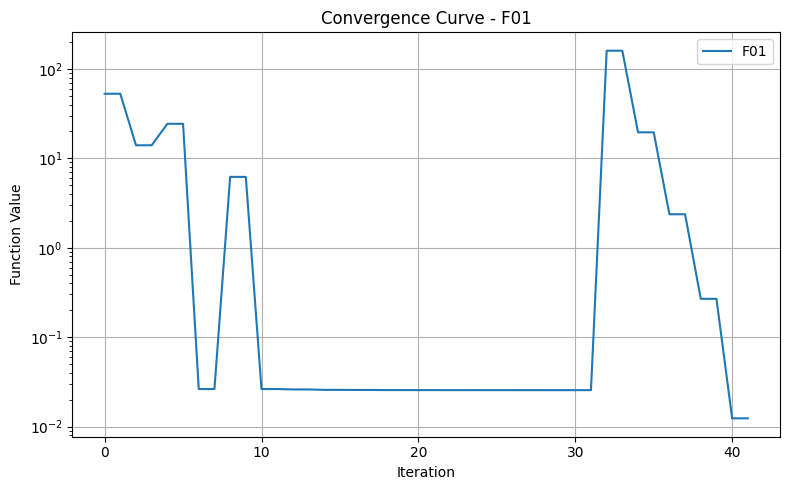

Running F02 (dim=1)...


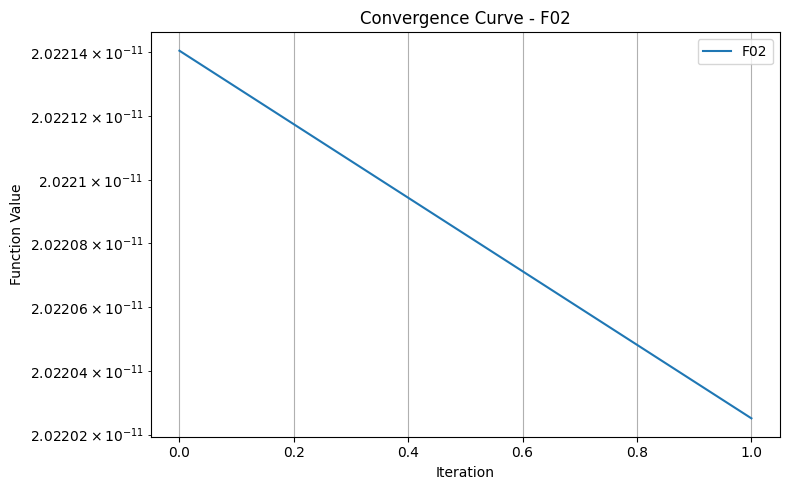

Running F03 (dim=1)...


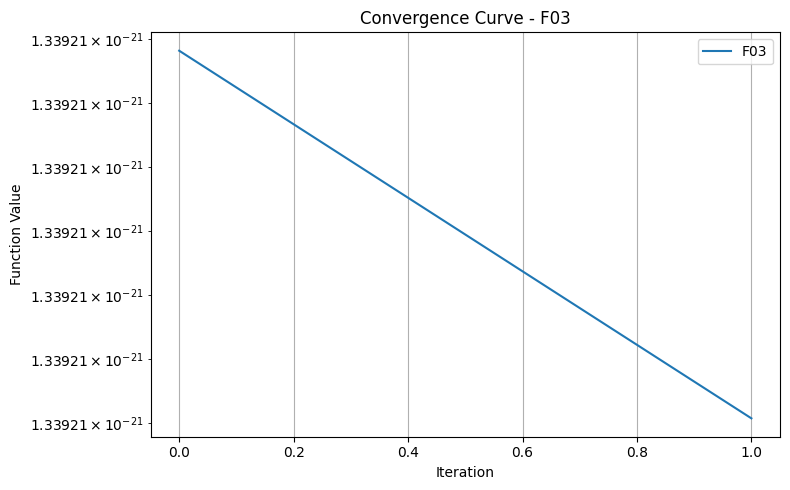

Running F04 (dim=2)...


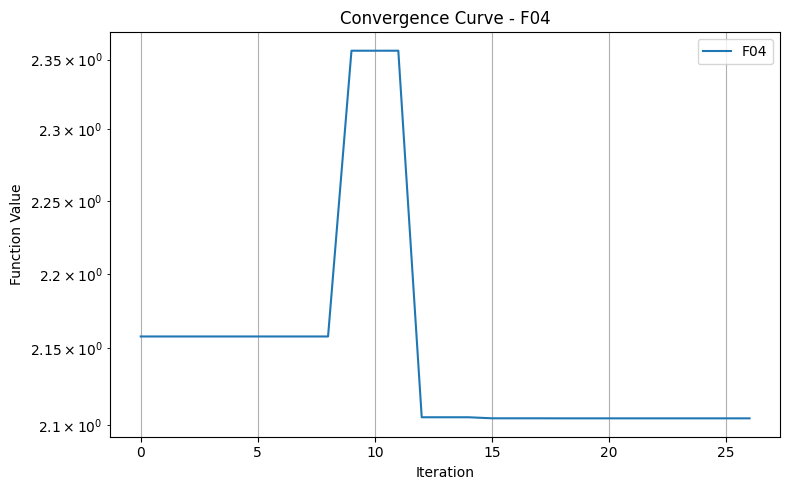

Running F05 (dim=2)...


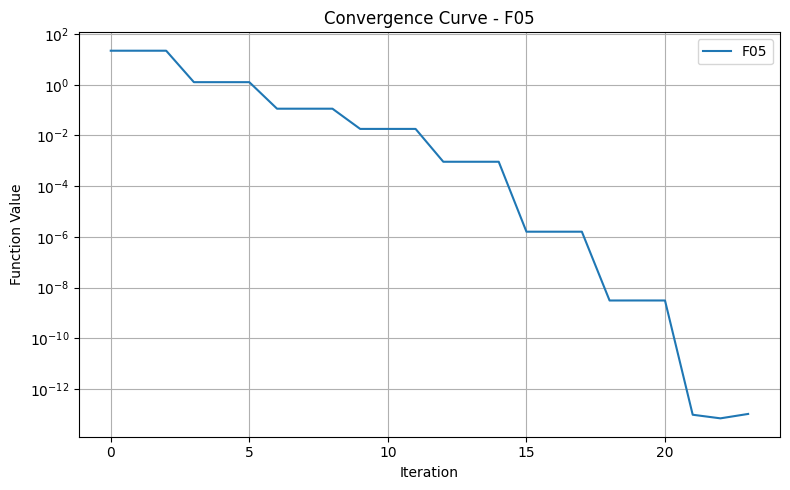

Running F06 (dim=2)...


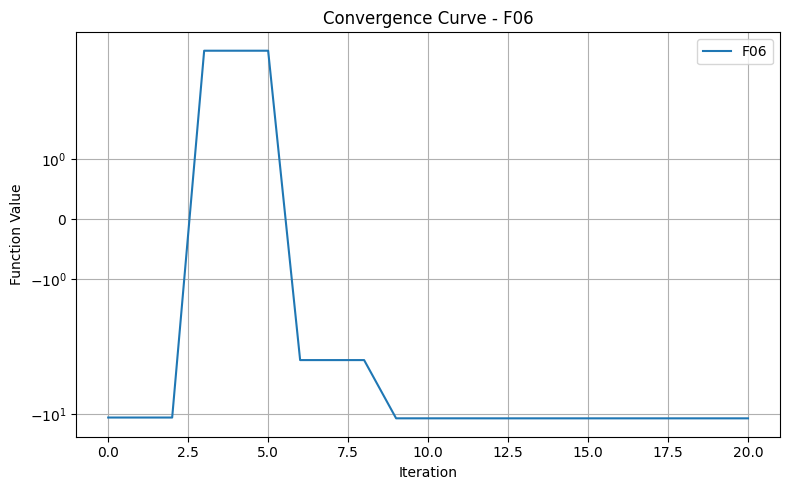

Running F07 (dim=2)...


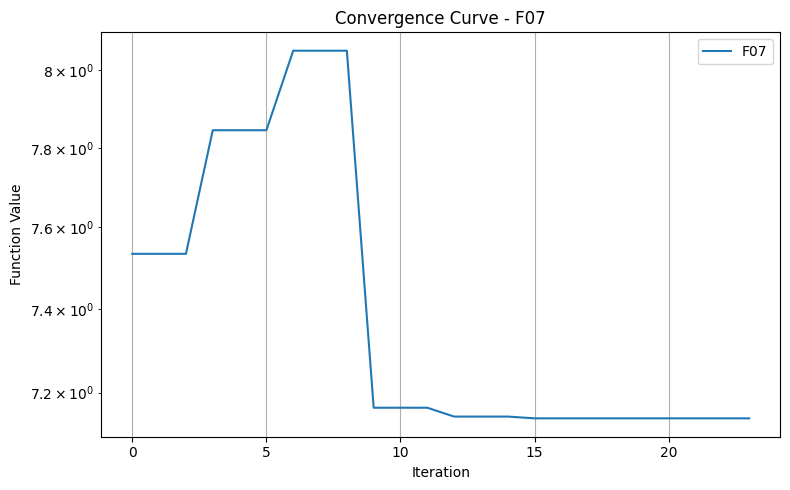

Running F08 (dim=2)...


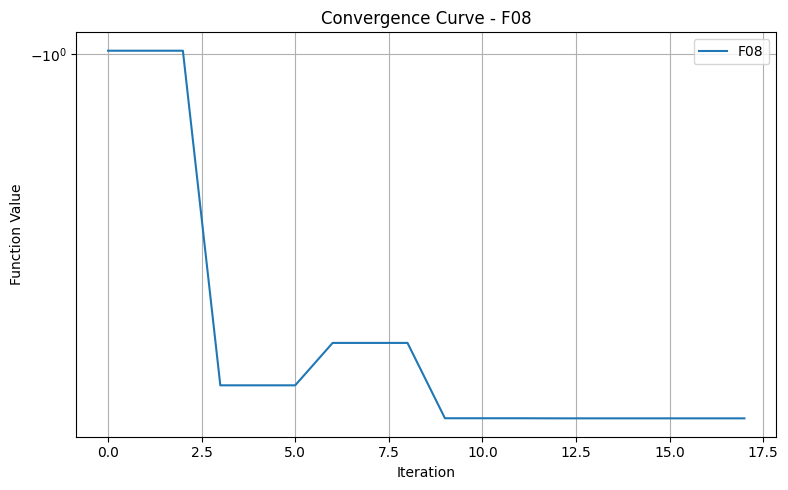

Running F09 (dim=2)...


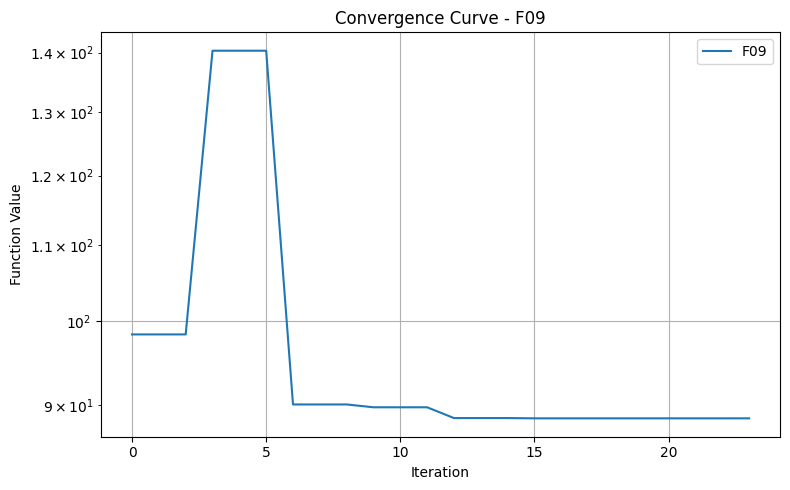

Running F10 (dim=3)...


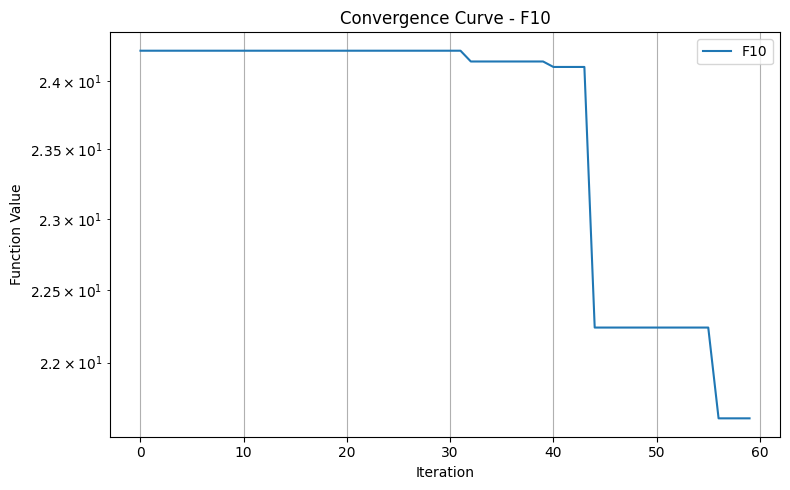

Running F11 (dim=2)...


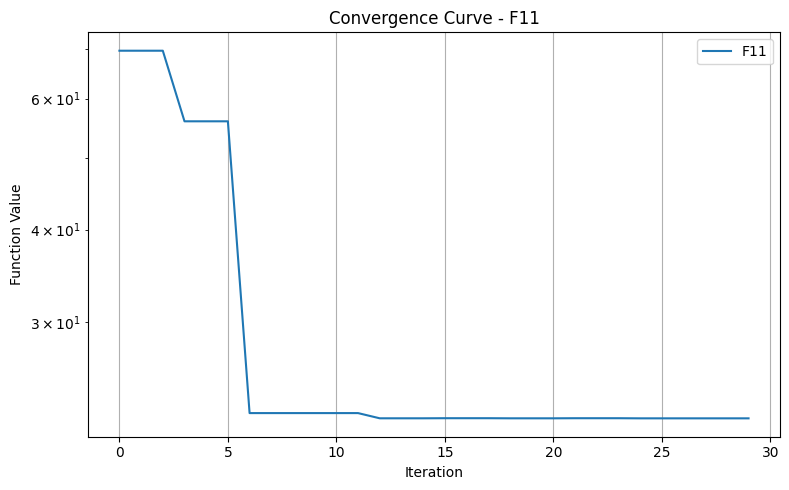

Running F12 (dim=5)...


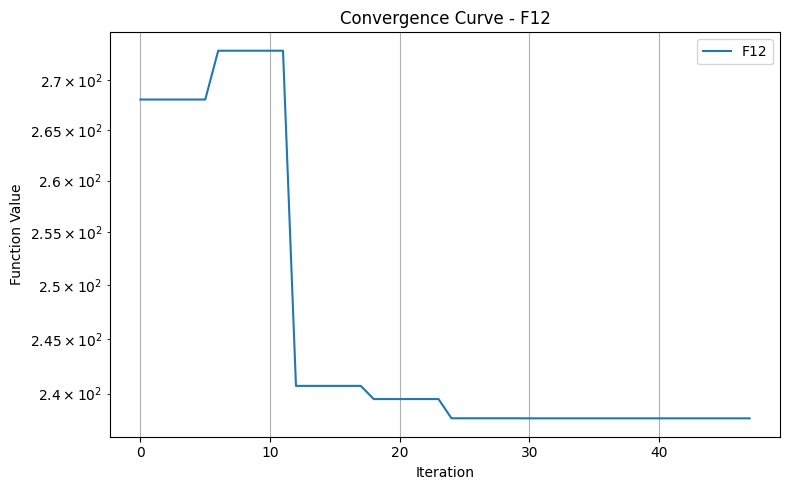


--- Benchmark Results ---
                  Best          Mean        Median         Worst           STD
Function                                                                      
F01       8.927969e-11  1.026297e-02  1.142619e-07  1.739752e-01  3.408175e-02
F02       3.221599e-12  1.930130e-09  2.173331e-09  3.788925e-09  1.107105e-09
F03       5.590477e-83  9.085996e-09  4.928266e-28  2.240892e-07  4.007703e-08
F04      -7.799344e-01  3.333333e+08  2.104250e+00  1.000000e+10  1.795055e+09
F05       1.397274e-16  1.170854e+01  9.517095e-14  1.888943e+02  4.394305e+01
F06      -1.867309e+02 -3.191683e+01 -1.097491e+01 -5.471530e-01  5.283882e+01
F07       2.197473e-01  7.185008e+00  4.284523e+00  2.605733e+01  7.235351e+00
F08      -2.000000e+00 -2.000000e+00 -2.000000e+00 -2.000000e+00  4.442568e-12
F09       9.949591e-01  3.333334e+08  6.616305e+01  1.000000e+10  1.795055e+09
F10       6.051520e+00  2.666667e+09  2.043135e+01  1.000000e+10  4.422166e+09
F11       2.227924e+01  2

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- Custom Benchmark Functions ---
def Five_Uneven_Peak_Trap(x):
    x = x[0]
    if x < 0 or x > 15:
        return 1e10
    if x < 2.5:
        return 80 * (2.5 - x)
    elif x < 5:
        return 64 * (x - 2.5)
    elif x < 7.5:
        return 64 * (7.5 - x)
    elif x < 12.5:
        return 28 * (x - 7.5)
    else:
        return 28 * (15 - x)

def Equal_Maxima(x):
    x = x[0]
    return np.sin(5 * np.pi * x) ** 6

def Uneven_Decreasing_Maxima(x):
    x = x[0]
    if x < 0:
        return 1e10
    return np.exp(-2 * np.log(2) * ((x - 0.08) / 0.854) ** 2) * np.sin(5 * np.pi * (x ** 0.75 - 0.05)) ** 6

def Six_Hump_Camel_Back(x):
    x1, x2 = x
    return (4 - 2.1 * x1**2 + x1**4 / 3) * x1**2 + x1 * x2 + (-4 + 4 * x2**2) * x2**2

def Himmelblau(x):
    x1, x2 = x
    return (x1**2 + x2 - 11) ** 2 + (x1 + x2**2 - 7) ** 2

def Shubert(x):
    x = np.asarray(x)
    result = 1
    for i in range(len(x)):
        s = 0
        for j in range(1, 6):
            s += j * np.cos((j + 1) * x[i] + j)
        result *= s
    return result

def Composition_Function_1(x):
    return np.sum((x - 1)**2) + np.sum(np.sin(3 * np.pi * x)**2)

def Vincent(x):
    x = np.asarray(x)
    if np.any(x <= 0):
        return 1e10
    return -np.sum(np.sin(10 * np.log(x)))

def Modified_Rastrigin_All_Global_Optima(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum((x - 0.1)**2 - 10 * np.cos(2 * np.pi * (x - 0.1)))

def Composition_Function_4(x):
    return np.sum(np.abs(x)) + np.prod(np.abs(x))

def Composition_Function_2(x):
    return np.sum((x + 1)**2) + np.sum(np.cos(2 * np.pi * (x + 1))) + 10 * len(x)

def Composition_Function_3(x):
    return np.sum(x**2 - 10 * np.cos(2 * np.pi * x)) + 10 * len(x)

benchmark_functions = {
    "F01": Five_Uneven_Peak_Trap,
    "F02": Equal_Maxima,
    "F03": Uneven_Decreasing_Maxima,
    "F04": Six_Hump_Camel_Back,
    "F05": Himmelblau,
    "F06": Shubert,
    "F07": Composition_Function_1,
    "F08": Vincent,
    "F09": Modified_Rastrigin_All_Global_Optima,
    "F10": Composition_Function_4,
    "F11": Composition_Function_2,
    "F12": Composition_Function_3
}

# --- L-BFGS-B Optimizer with Bounds and Penalty ---
def lbgfsb(func, initial_guess, bounds=None):
    convergence_curve = []

    def wrapped_func(x):
        # Penalize out-of-bounds values
        if bounds is not None:
            for i, (lb, ub) in enumerate(bounds):
                if x[i] < lb or x[i] > ub:
                    return 1e10
        val = func(x)
        if not np.isfinite(val) or val > 1e10:
            return 1e10
        convergence_curve.append(val)
        return val

    result = minimize(
        fun=wrapped_func,
        x0=initial_guess,
        method='L-BFGS-B',
        options={'maxiter': 1000, 'disp': False}
    )
    return result.x, result.fun, convergence_curve

# --- Run Single Benchmark ---
def run_benchmark(func, dim, runs=30, low=0.1, high=10):
    results = []
    convergence = None
    bounds = [(low, high)] * dim
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, val, curve = lbgfsb(func, x0, bounds=bounds)
            if np.isfinite(val):
                results.append(val)
                if convergence is None or (len(curve) < len(convergence)):
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    dim_dict = {
        "F01": 1, "F02": 1, "F03": 1,
        "F04": 2, "F05": 2, "F06": 2,
        "F07": 2, "F08": 2, "F09": 2,
        "F10": 3, "F11": 2, "F12": 5
    }
    for name, func in benchmark_functions.items():
        d = dim_dict.get(name, dim)
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All Benchmarks ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# --- Save to Excel ---
results.to_excel('Benchmark_Custom_L-BFGS-B.xlsx')
print("\n✅ Results saved to Benchmark_Custom_L-BFGS-B.xlsx")

Running F01 (dim=1)...


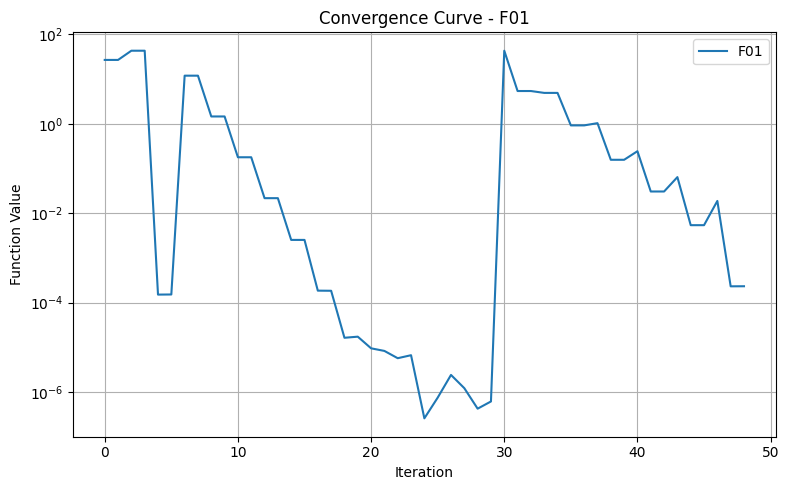

Running F02 (dim=1)...


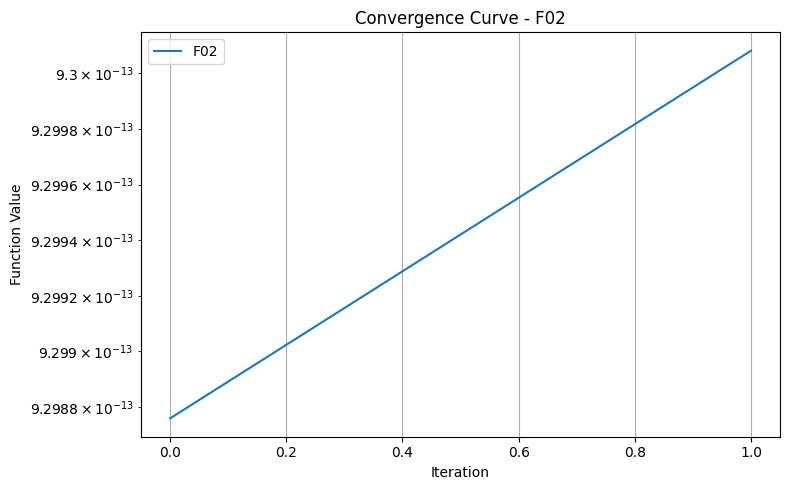

Running F03 (dim=1)...


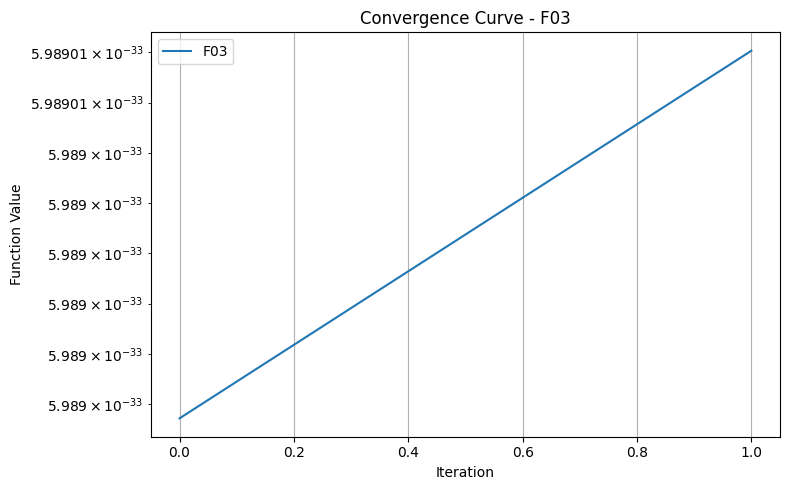

Running F04 (dim=2)...


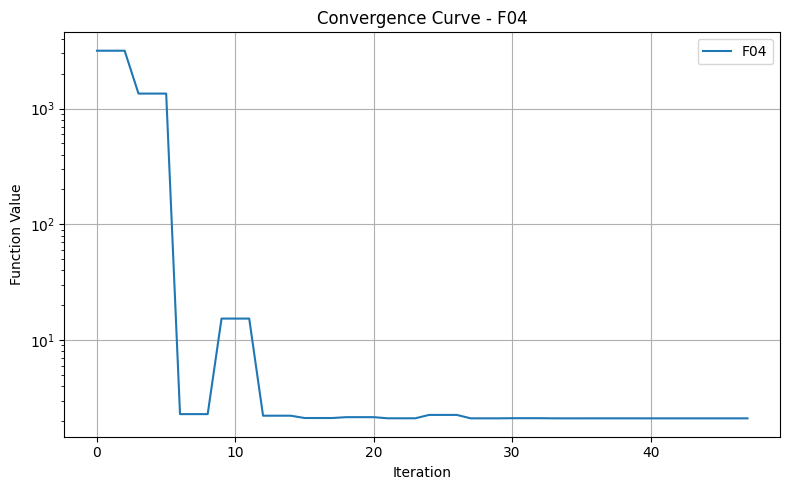

Running F05 (dim=2)...


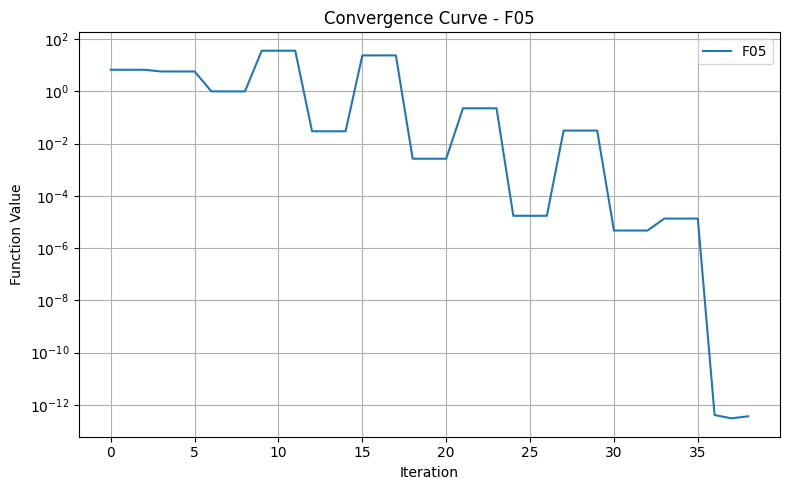

Running F06 (dim=2)...


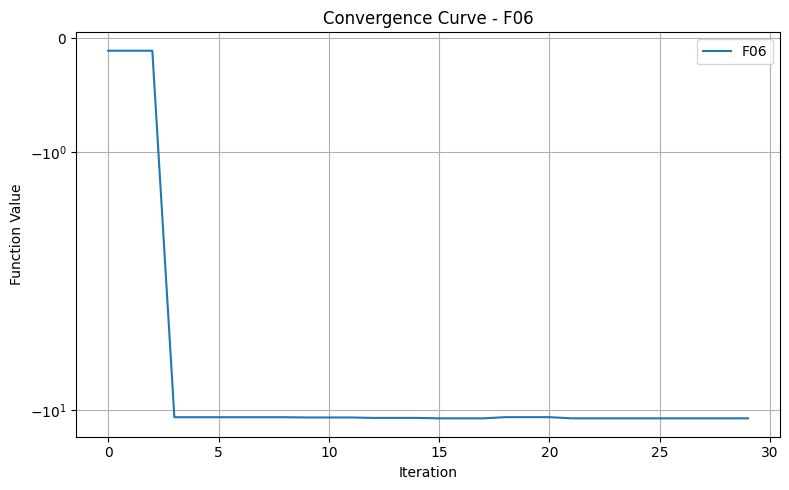

Running F07 (dim=2)...


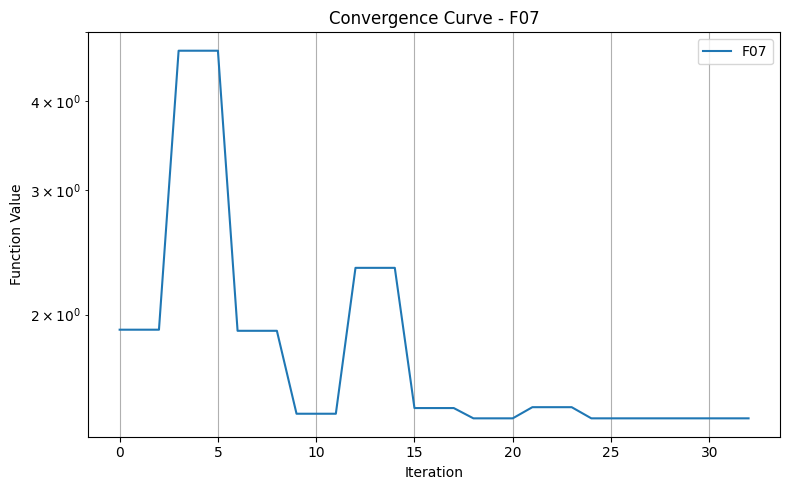

Running F08 (dim=2)...


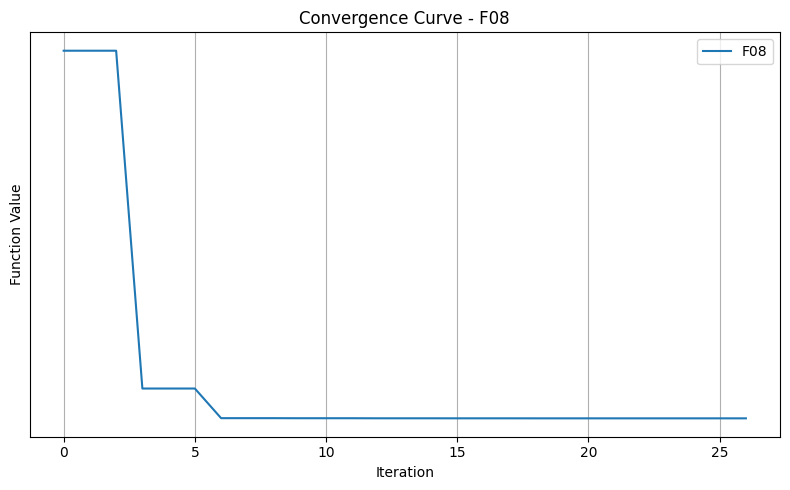

Running F09 (dim=2)...


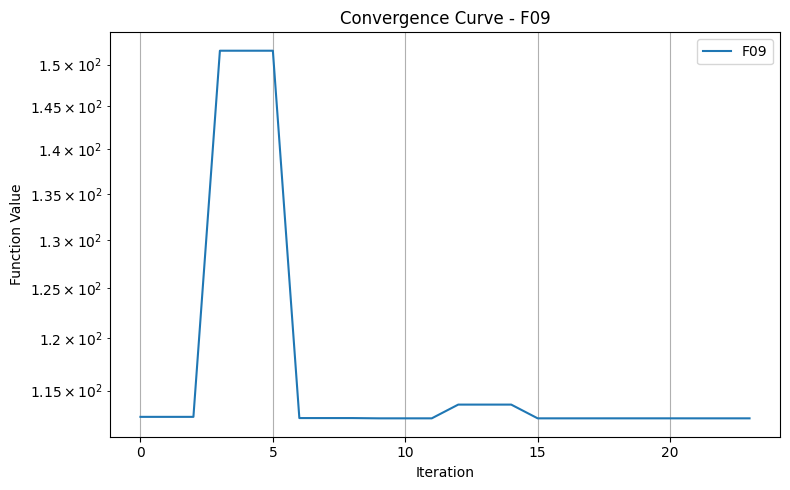

Running F10 (dim=3)...


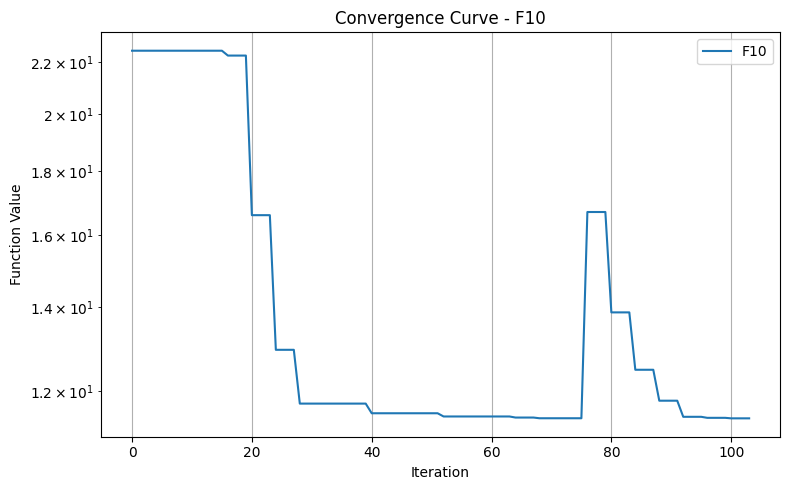

Running F11 (dim=2)...


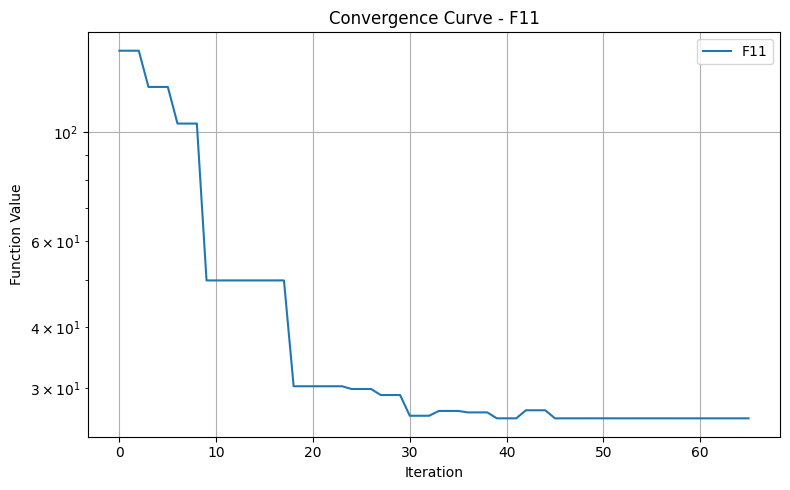

Running F12 (dim=5)...


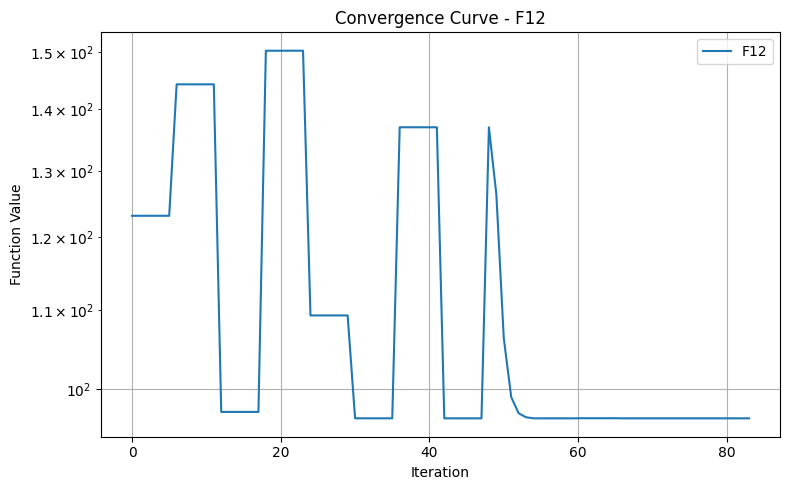


--- Benchmark Results ---
                  Best        Mean        Median        Worst           STD
Function                                                                   
F01       2.073219e-07   38.404611  2.639933e+01   158.213919  4.483200e+01
F02       7.132939e-16    0.055068  6.659669e-10     0.932755  2.054321e-01
F03       1.621492e-71    0.000673  1.347897e-24     0.015808  2.918641e-03
F04      -8.775379e-01    1.399928  2.104250e+00     2.459463  1.267757e+00
F05       1.608709e-15   83.721850  1.919892e-14  1265.309695  2.647418e+02
F06      -3.958874e+01  -16.442115 -1.214215e+01    29.503020  1.432293e+01
F07       1.098737e-01    8.358547  4.064660e+00    64.173155  1.273495e+01
F08      -2.000000e+00   -2.000000 -2.000000e+00    -2.000000  5.633859e-12
F09       1.691420e+01   71.678315  7.103792e+01   186.165011  4.266600e+01
F10       7.142513e+00   63.002963  3.192935e+01   294.878860  7.200725e+01
F11       2.227924e+01   35.431497  2.607153e+01   145.638199

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- Custom Benchmark Functions ---
def Five_Uneven_Peak_Trap(x):
    x = x[0]
    if x < 0 or x > 15:
        return 1e10
    if x < 2.5:
        return 80 * (2.5 - x)
    elif x < 5:
        return 64 * (x - 2.5)
    elif x < 7.5:
        return 64 * (7.5 - x)
    elif x < 12.5:
        return 28 * (x - 7.5)
    else:
        return 28 * (15 - x)

def Equal_Maxima(x):
    x = x[0]
    return np.sin(5 * np.pi * x) ** 6

def Uneven_Decreasing_Maxima(x):
    x = x[0]
    if x < 0:
        return 1e10
    return np.exp(-2 * np.log(2) * ((x - 0.08) / 0.854) ** 2) * np.sin(5 * np.pi * (x ** 0.75 - 0.05)) ** 6

def Six_Hump_Camel_Back(x):
    x1, x2 = x
    return (4 - 2.1 * x1**2 + x1**4 / 3) * x1**2 + x1 * x2 + (-4 + 4 * x2**2) * x2**2

def Himmelblau(x):
    x1, x2 = x
    return (x1**2 + x2 - 11) ** 2 + (x1 + x2**2 - 7) ** 2

def Shubert(x):
    x = np.asarray(x)
    result = 1
    for i in range(len(x)):
        s = 0
        for j in range(1, 6):
            s += j * np.cos((j + 1) * x[i] + j)
        result *= s
    return result

def Composition_Function_1(x):
    return np.sum((x - 1)**2) + np.sum(np.sin(3 * np.pi * x)**2)

def Vincent(x):
    x = np.asarray(x)
    if np.any(x <= 0):
        return 1e10
    return -np.sum(np.sin(10 * np.log(x)))

def Modified_Rastrigin_All_Global_Optima(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum((x - 0.1)**2 - 10 * np.cos(2 * np.pi * (x - 0.1)))

def Composition_Function_4(x):
    return np.sum(np.abs(x)) + np.prod(np.abs(x))

def Composition_Function_2(x):
    return np.sum((x + 1)**2) + np.sum(np.cos(2 * np.pi * (x + 1))) + 10 * len(x)

def Composition_Function_3(x):
    return np.sum(x**2 - 10 * np.cos(2 * np.pi * x)) + 10 * len(x)

benchmark_functions = {
    "F01": Five_Uneven_Peak_Trap,
    "F02": Equal_Maxima,
    "F03": Uneven_Decreasing_Maxima,
    "F04": Six_Hump_Camel_Back,
    "F05": Himmelblau,
    "F06": Shubert,
    "F07": Composition_Function_1,
    "F08": Vincent,
    "F09": Modified_Rastrigin_All_Global_Optima,
    "F10": Composition_Function_4,
    "F11": Composition_Function_2,
    "F12": Composition_Function_3
}

# --- CG Optimizer with Bounds and Penalty ---
def cg(func, initial_guess, bounds=None):
    convergence_curve = []

    def wrapped_func(x):
        # Penalize out-of-bounds values
        if bounds is not None:
            for i, (lb, ub) in enumerate(bounds):
                if x[i] < lb or x[i] > ub:
                    return 1e10
        val = func(x)
        if not np.isfinite(val) or val > 1e10:
            return 1e10
        convergence_curve.append(val)
        return val

    result = minimize(
        fun=wrapped_func,
        x0=initial_guess,
        method='CG',
        options={'maxiter': 1000, 'disp': False}
    )
    return result.x, result.fun, convergence_curve

# --- Run Single Benchmark ---
def run_benchmark(func, dim, runs=30, low=0.1, high=10):
    results = []
    convergence = None
    bounds = [(low, high)] * dim
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, val, curve = cg(func, x0, bounds=bounds)
            if np.isfinite(val):
                results.append(val)
                if convergence is None or (len(curve) < len(convergence)):
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    dim_dict = {
        "F01": 1, "F02": 1, "F03": 1,
        "F04": 2, "F05": 2, "F06": 2,
        "F07": 2, "F08": 2, "F09": 2,
        "F10": 3, "F11": 2, "F12": 5
    }
    for name, func in benchmark_functions.items():
        d = dim_dict.get(name, dim)
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All Benchmarks ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# --- Save to Excel ---
results.to_excel('Benchmark_Custom_CG.xlsx')
print("\n✅ Results saved to Benchmark_Custom_CG.xlsx")

Running F01 (dim=1)...


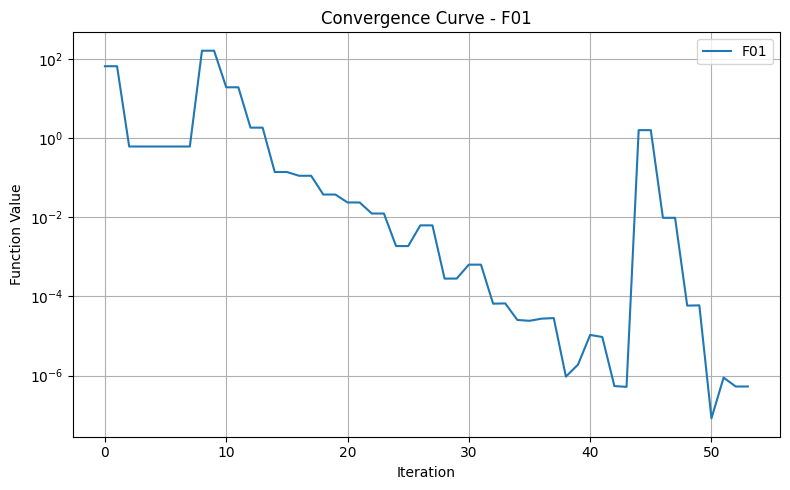

Running F02 (dim=1)...


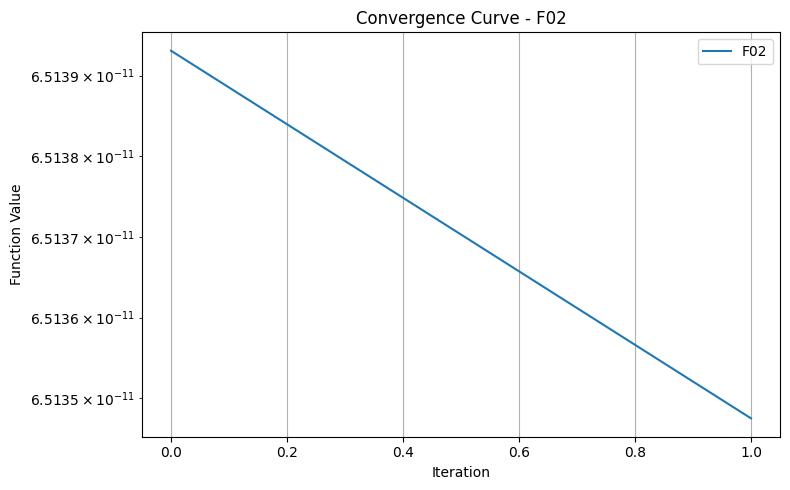

Running F03 (dim=1)...


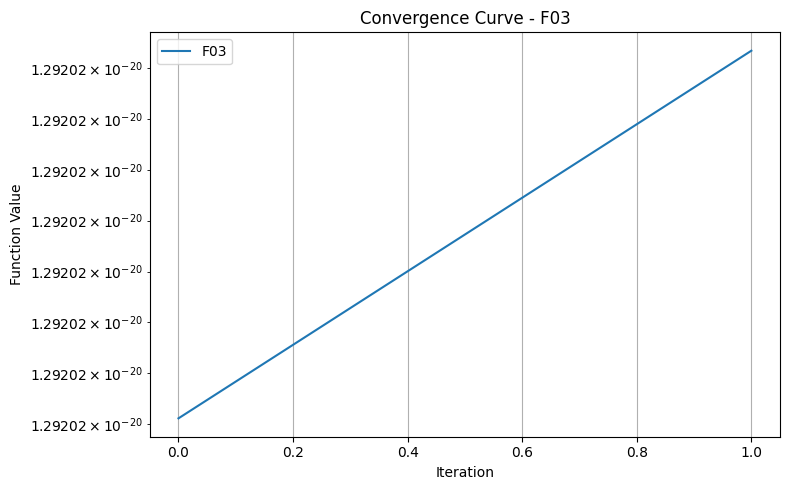

Running F04 (dim=2)...


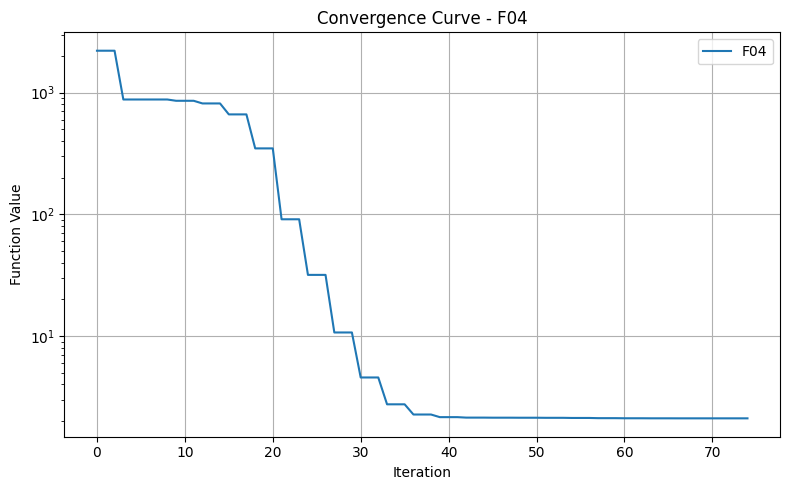

Running F05 (dim=2)...


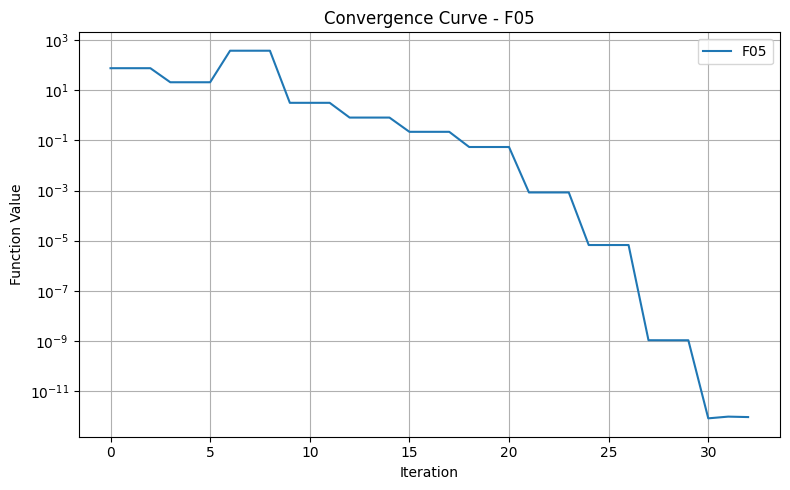

Running F06 (dim=2)...


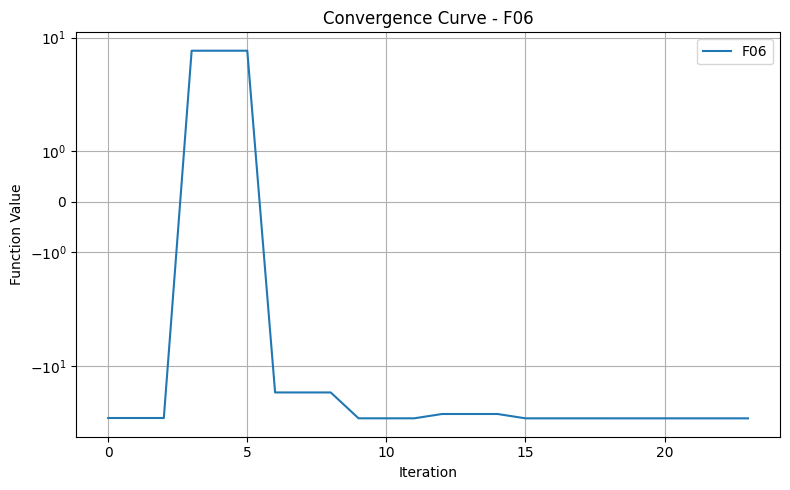

Running F07 (dim=2)...


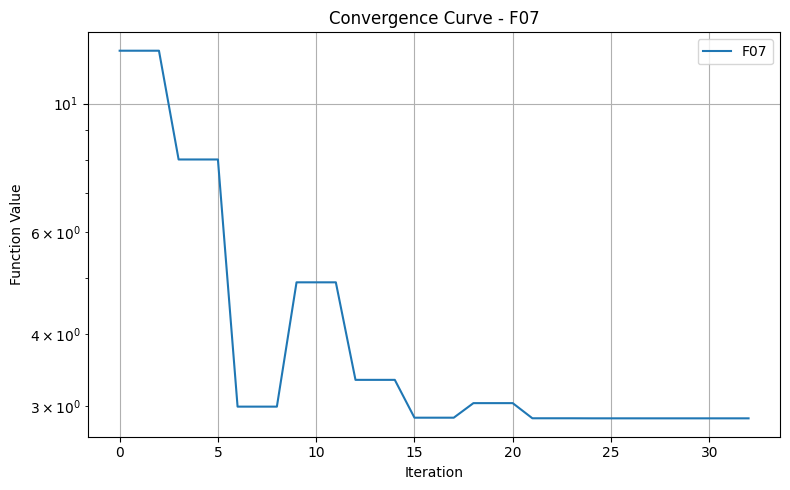

Running F08 (dim=2)...


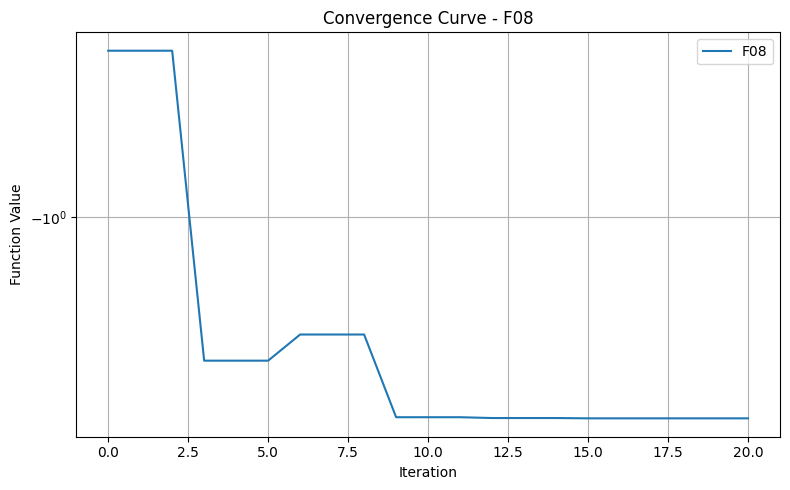

Running F09 (dim=2)...


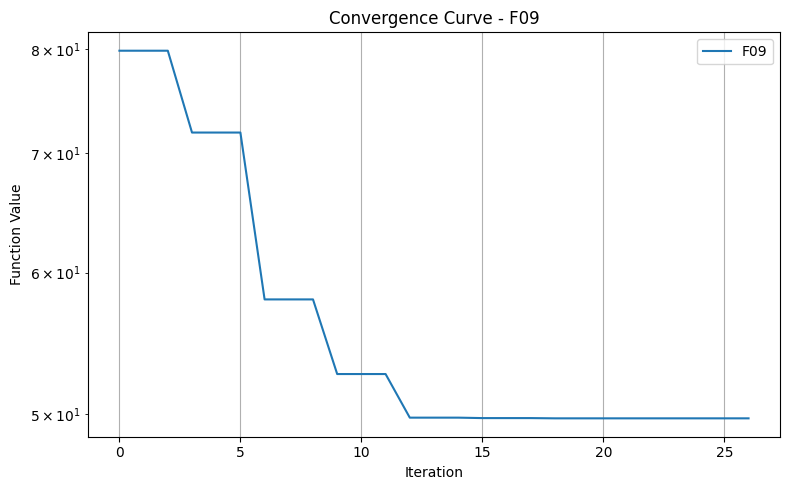

Running F10 (dim=3)...


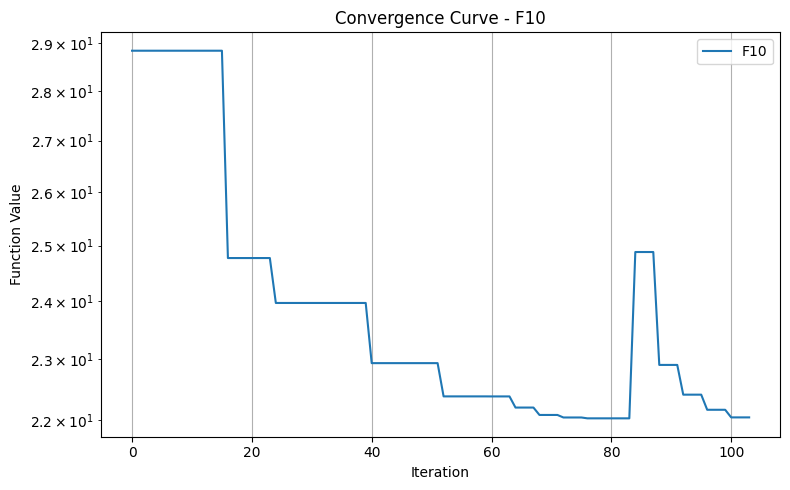

Running F11 (dim=2)...


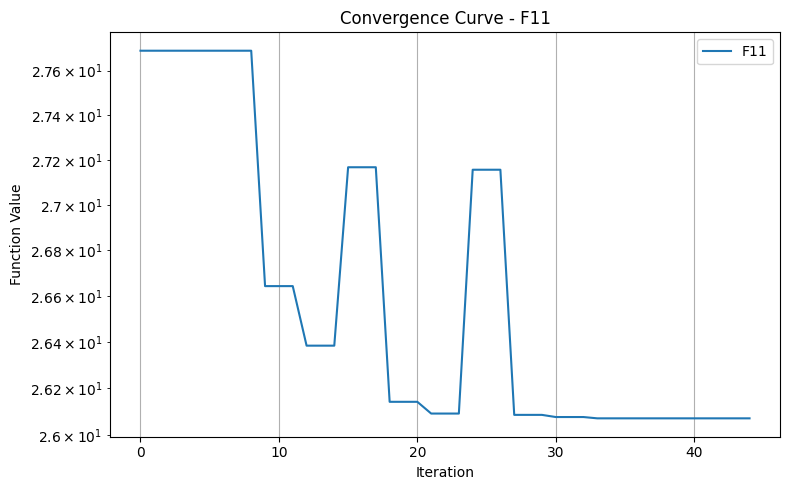

Running F12 (dim=5)...


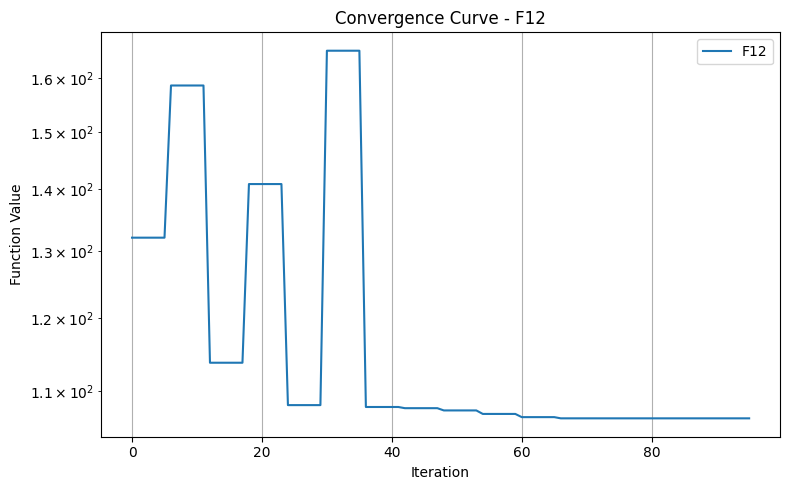


--- Benchmark Results ---
                  Best          Mean        Median         Worst           STD
Function                                                                      
F01       4.829144e-08  6.597597e-01  1.456217e-07  1.864302e+01  3.345771e+00
F02       1.236472e-14  1.995245e-09  2.263312e-09  4.086961e-09  1.362440e-09
F03       1.021722e-74  2.422996e-09  2.802029e-16  1.750833e-08  4.695409e-09
F04      -7.556717e-01  3.549283e+03  3.574579e+00  7.596729e+04  1.413796e+04
F05       3.882462e-16  2.992678e+02  3.614357e-14  3.602109e+03  7.942362e+02
F06      -1.235768e+02 -2.389566e+01 -1.535678e+01 -8.769076e+00  2.169552e+01
F07       1.361049e-14  7.266609e+00  2.856404e+00  4.874019e+01  1.018265e+01
F08      -2.000000e+00 -1.916723e+00 -2.000000e+00  4.983201e-01  4.484622e-01
F09       9.949591e-01  5.464622e+01  4.987256e+01  1.250102e+02  3.372337e+01
F10       4.745216e+00  8.739824e+01  5.056458e+01  6.020973e+02  1.203372e+02
F11       2.227924e+01  3

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- Custom Benchmark Functions ---
def Five_Uneven_Peak_Trap(x):
    x = x[0]
    if x < 0 or x > 15:
        return 1e10
    if x < 2.5:
        return 80 * (2.5 - x)
    elif x < 5:
        return 64 * (x - 2.5)
    elif x < 7.5:
        return 64 * (7.5 - x)
    elif x < 12.5:
        return 28 * (x - 7.5)
    else:
        return 28 * (15 - x)

def Equal_Maxima(x):
    x = x[0]
    return np.sin(5 * np.pi * x) ** 6

def Uneven_Decreasing_Maxima(x):
    x = x[0]
    if x < 0:
        return 1e10
    return np.exp(-2 * np.log(2) * ((x - 0.08) / 0.854) ** 2) * np.sin(5 * np.pi * (x ** 0.75 - 0.05)) ** 6

def Six_Hump_Camel_Back(x):
    x1, x2 = x
    return (4 - 2.1 * x1**2 + x1**4 / 3) * x1**2 + x1 * x2 + (-4 + 4 * x2**2) * x2**2

def Himmelblau(x):
    x1, x2 = x
    return (x1**2 + x2 - 11) ** 2 + (x1 + x2**2 - 7) ** 2

def Shubert(x):
    x = np.asarray(x)
    result = 1
    for i in range(len(x)):
        s = 0
        for j in range(1, 6):
            s += j * np.cos((j + 1) * x[i] + j)
        result *= s
    return result

def Composition_Function_1(x):
    return np.sum((x - 1)**2) + np.sum(np.sin(3 * np.pi * x)**2)

def Vincent(x):
    x = np.asarray(x)
    if np.any(x <= 0):
        return 1e10
    return -np.sum(np.sin(10 * np.log(x)))

def Modified_Rastrigin_All_Global_Optima(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum((x - 0.1)**2 - 10 * np.cos(2 * np.pi * (x - 0.1)))

def Composition_Function_4(x):
    return np.sum(np.abs(x)) + np.prod(np.abs(x))

def Composition_Function_2(x):
    return np.sum((x + 1)**2) + np.sum(np.cos(2 * np.pi * (x + 1))) + 10 * len(x)

def Composition_Function_3(x):
    return np.sum(x**2 - 10 * np.cos(2 * np.pi * x)) + 10 * len(x)

benchmark_functions = {
    "F01": Five_Uneven_Peak_Trap,
    "F02": Equal_Maxima,
    "F03": Uneven_Decreasing_Maxima,
    "F04": Six_Hump_Camel_Back,
    "F05": Himmelblau,
    "F06": Shubert,
    "F07": Composition_Function_1,
    "F08": Vincent,
    "F09": Modified_Rastrigin_All_Global_Optima,
    "F10": Composition_Function_4,
    "F11": Composition_Function_2,
    "F12": Composition_Function_3
}

# --- BFGS Optimizer with Bounds and Penalty ---
def bgfs(func, initial_guess, bounds=None):
    convergence_curve = []

    def wrapped_func(x):
        # Penalize out-of-bounds values
        if bounds is not None:
            for i, (lb, ub) in enumerate(bounds):
                if x[i] < lb or x[i] > ub:
                    return 1e10
        val = func(x)
        if not np.isfinite(val) or val > 1e10:
            return 1e10
        convergence_curve.append(val)
        return val

    result = minimize(
        fun=wrapped_func,
        x0=initial_guess,
        method='BFGS',
        options={'maxiter': 1000, 'disp': False}
    )
    return result.x, result.fun, convergence_curve

# --- Run Single Benchmark ---
def run_benchmark(func, dim, runs=30, low=0.1, high=10):
    results = []
    convergence = None
    bounds = [(low, high)] * dim
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, val, curve = bgfs(func, x0, bounds=bounds)
            if np.isfinite(val):
                results.append(val)
                if convergence is None or (len(curve) < len(convergence)):
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    dim_dict = {
        "F01": 1, "F02": 1, "F03": 1,
        "F04": 2, "F05": 2, "F06": 2,
        "F07": 2, "F08": 2, "F09": 2,
        "F10": 3, "F11": 2, "F12": 5
    }
    for name, func in benchmark_functions.items():
        d = dim_dict.get(name, dim)
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All Benchmarks ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# --- Save to Excel ---
results.to_excel('Benchmark_Custom_BFGS.xlsx')
print("\n✅ Results saved to Benchmark_Custom_BFGS.xlsx")

Running F01 (dim=1)...


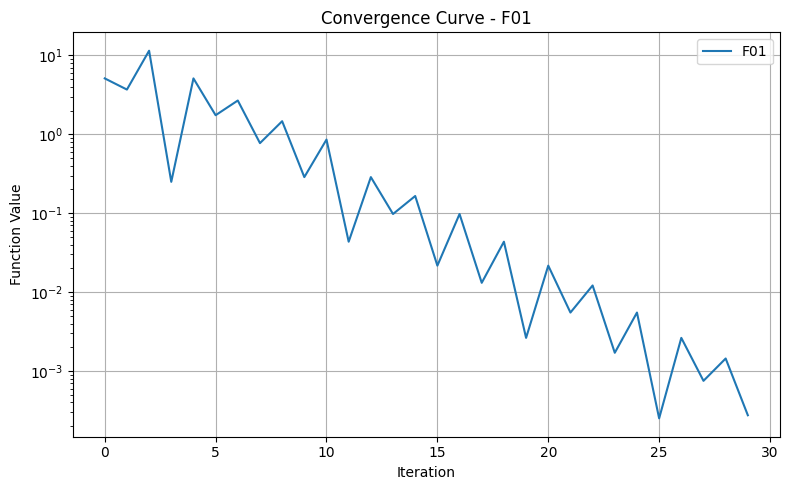

Running F02 (dim=1)...


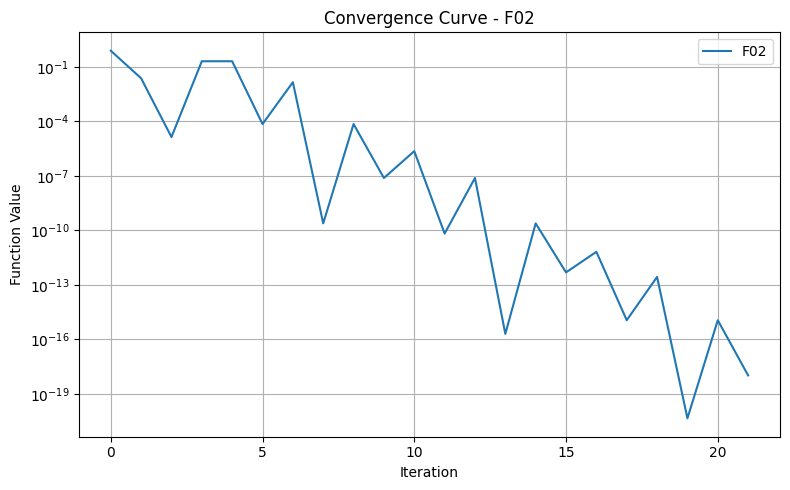

Running F03 (dim=1)...


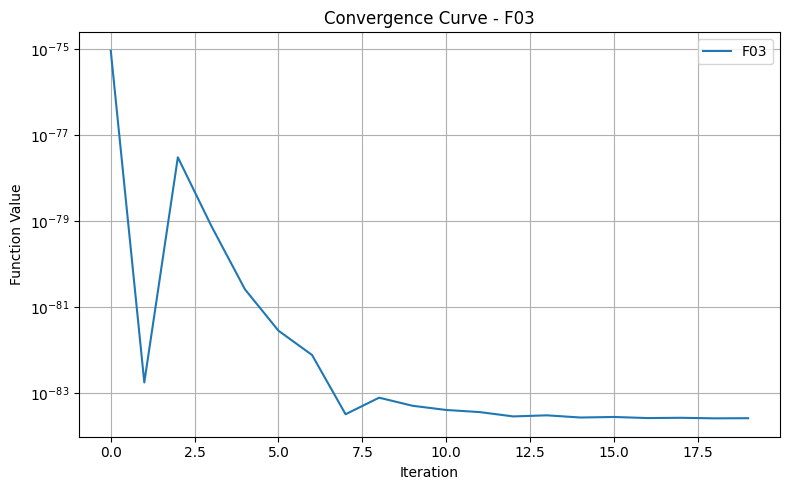

Running F04 (dim=2)...


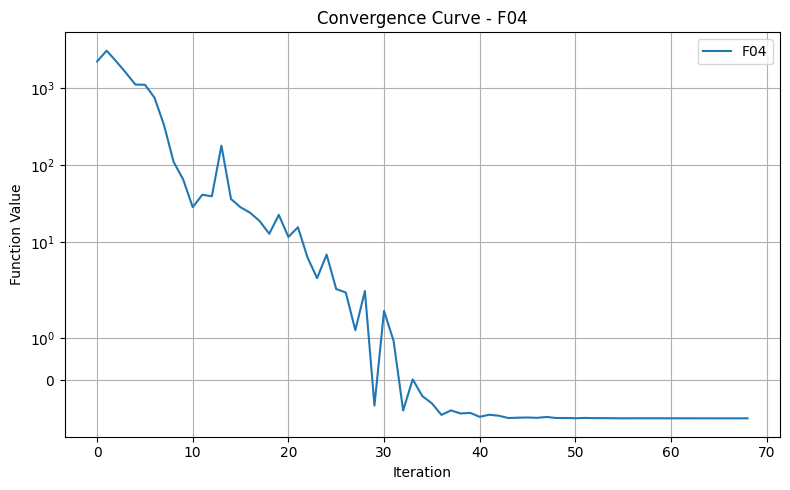

Running F05 (dim=2)...


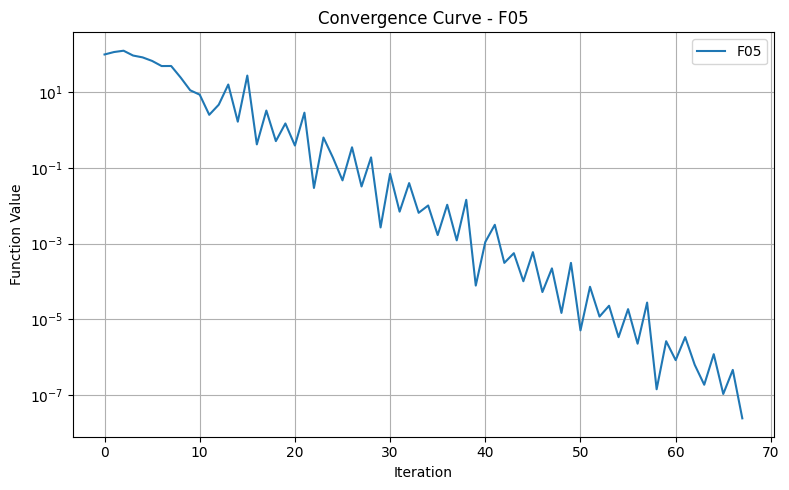

Running F06 (dim=2)...


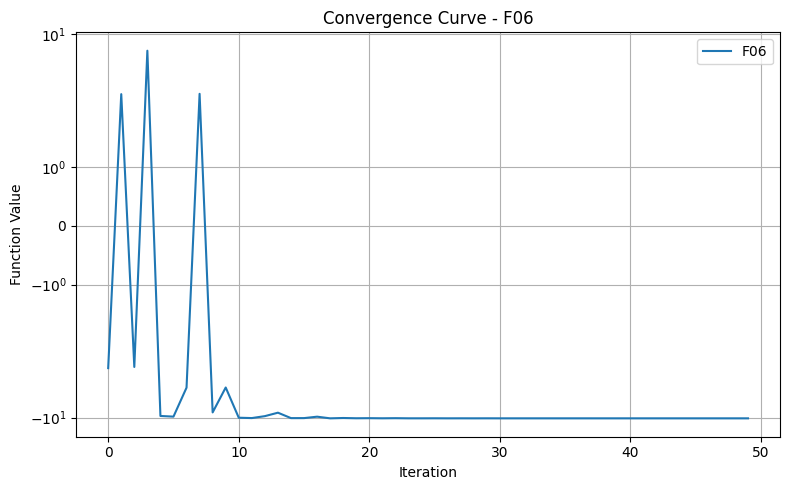

Running F07 (dim=2)...


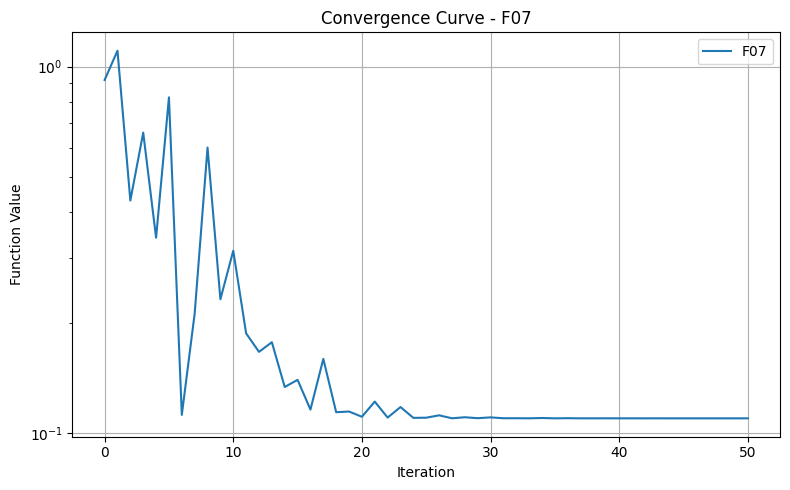

Running F08 (dim=2)...


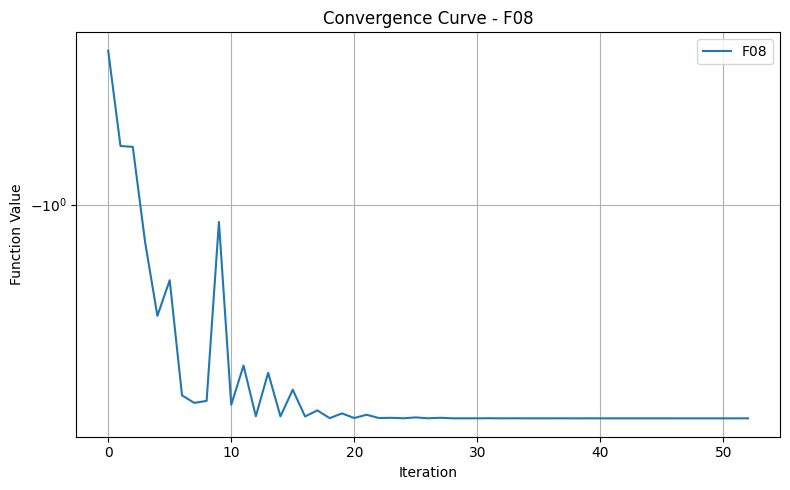

Running F09 (dim=2)...


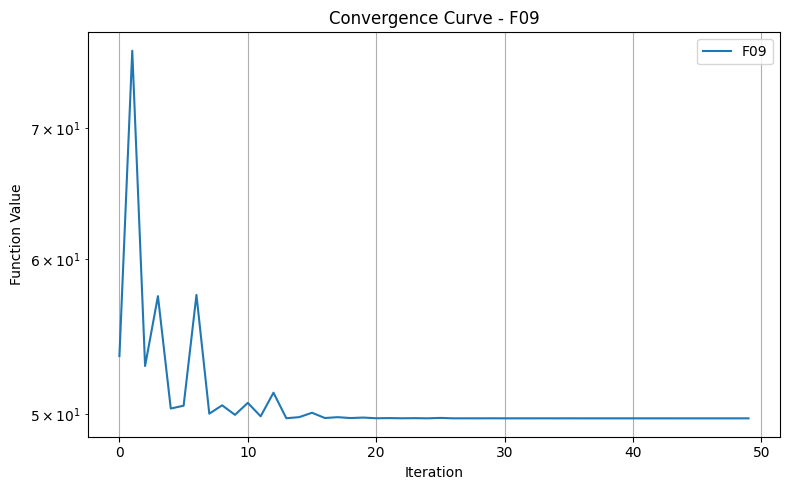

Running F10 (dim=3)...


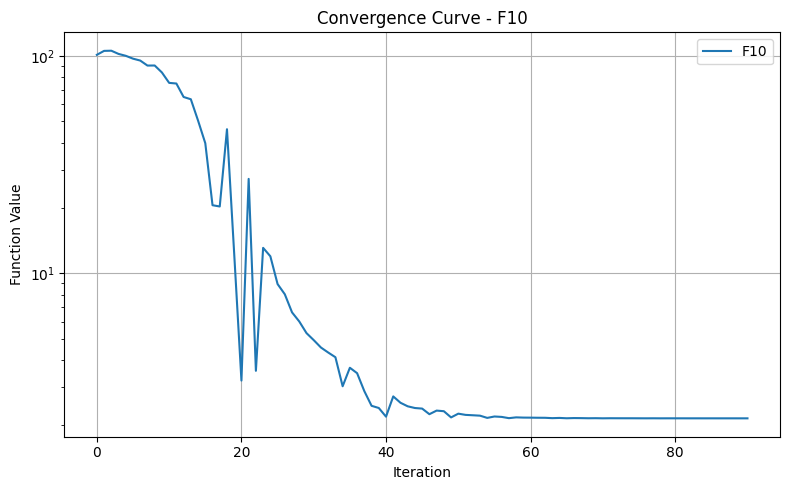

Running F11 (dim=2)...


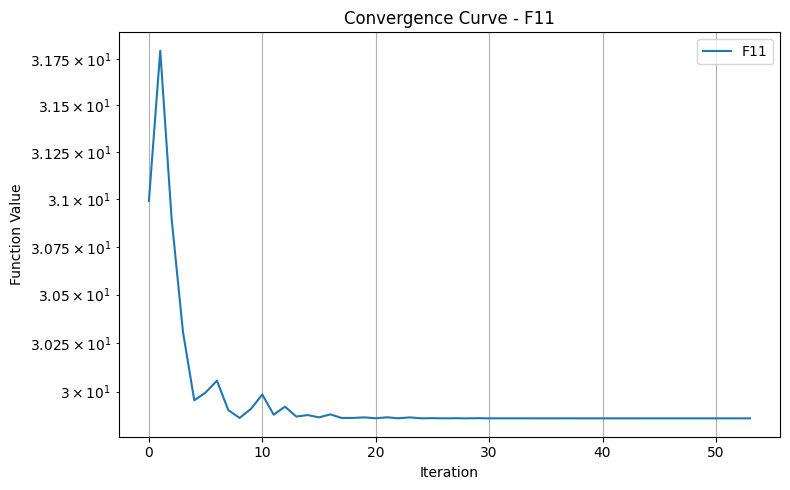

Running F12 (dim=5)...


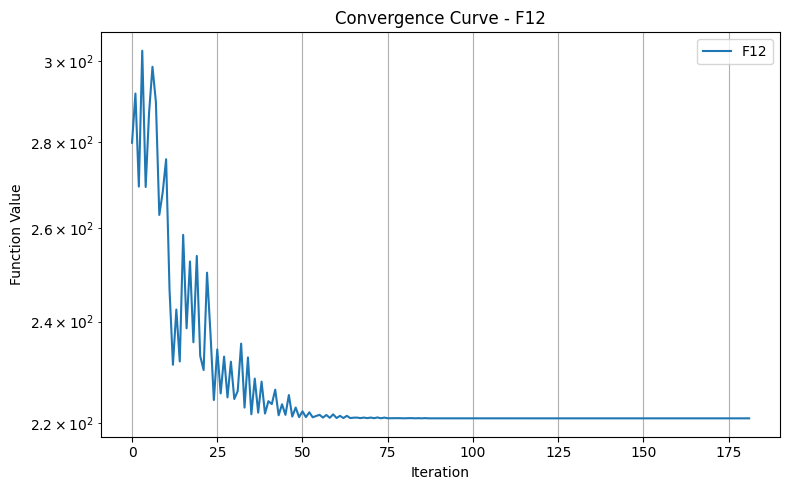


--- Benchmark Results ---
                   Best          Mean        Median         Worst  \
Function                                                            
F01        4.377866e-08  1.219607e-04  6.366939e-05  6.895570e-04   
F02        7.549619e-32  3.898951e-21  5.006935e-22  3.703976e-20   
F03       3.382654e-106  3.647443e-22  6.301405e-45  1.069540e-20   
F04       -8.898143e-01  3.087578e-01 -8.895252e-01  2.104250e+00   
F05        7.993385e-09  2.612191e-08  2.360429e-08  6.141501e-08   
F06       -1.235768e+02 -2.538353e+01 -1.296482e+01 -2.447297e+00   
F07        2.537656e-08  1.863753e+00  2.197475e-01  1.076508e+01   
F08       -2.000000e+00 -2.000000e+00 -2.000000e+00 -2.000000e+00   
F09        9.949593e-01  6.625788e+01  5.123939e+01  1.805087e+02   
F10        4.483058e-01  3.807906e+00  3.652091e+00  9.228286e+00   
F11        2.227924e+01  2.354333e+01  2.227924e+01  2.986382e+01   
F12        1.392941e+01  1.608715e+02  1.527005e+02  3.313094e+02   

      

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- Custom Benchmark Functions ---
def Five_Uneven_Peak_Trap(x):
    x = x[0]
    if x < 0 or x > 15:
        return 1e10
    if x < 2.5:
        return 80 * (2.5 - x)
    elif x < 5:
        return 64 * (x - 2.5)
    elif x < 7.5:
        return 64 * (7.5 - x)
    elif x < 12.5:
        return 28 * (x - 7.5)
    else:
        return 28 * (15 - x)

def Equal_Maxima(x):
    x = x[0]
    return np.sin(5 * np.pi * x) ** 6

def Uneven_Decreasing_Maxima(x):
    x = x[0]
    if x < 0:
        return 1e10
    return np.exp(-2 * np.log(2) * ((x - 0.08) / 0.854) ** 2) * np.sin(5 * np.pi * (x ** 0.75 - 0.05)) ** 6

def Six_Hump_Camel_Back(x):
    x1, x2 = x
    return (4 - 2.1 * x1**2 + x1**4 / 3) * x1**2 + x1 * x2 + (-4 + 4 * x2**2) * x2**2

def Himmelblau(x):
    x1, x2 = x
    return (x1**2 + x2 - 11) ** 2 + (x1 + x2**2 - 7) ** 2

def Shubert(x):
    x = np.asarray(x)
    result = 1
    for i in range(len(x)):
        s = 0
        for j in range(1, 6):
            s += j * np.cos((j + 1) * x[i] + j)
        result *= s
    return result

def Composition_Function_1(x):
    return np.sum((x - 1)**2) + np.sum(np.sin(3 * np.pi * x)**2)

def Vincent(x):
    x = np.asarray(x)
    if np.any(x <= 0):
        return 1e10
    return -np.sum(np.sin(10 * np.log(x)))

def Modified_Rastrigin_All_Global_Optima(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum((x - 0.1)**2 - 10 * np.cos(2 * np.pi * (x - 0.1)))

def Composition_Function_4(x):
    return np.sum(np.abs(x)) + np.prod(np.abs(x))

def Composition_Function_2(x):
    return np.sum((x + 1)**2) + np.sum(np.cos(2 * np.pi * (x + 1))) + 10 * len(x)

def Composition_Function_3(x):
    return np.sum(x**2 - 10 * np.cos(2 * np.pi * x)) + 10 * len(x)

benchmark_functions = {
    "F01": Five_Uneven_Peak_Trap,
    "F02": Equal_Maxima,
    "F03": Uneven_Decreasing_Maxima,
    "F04": Six_Hump_Camel_Back,
    "F05": Himmelblau,
    "F06": Shubert,
    "F07": Composition_Function_1,
    "F08": Vincent,
    "F09": Modified_Rastrigin_All_Global_Optima,
    "F10": Composition_Function_4,
    "F11": Composition_Function_2,
    "F12": Composition_Function_3
}

# --- Nelder-Mead Optimizer with Bounds and Penalty ---
def nm(func, initial_guess, bounds=None):
    convergence_curve = []

    def wrapped_func(x):
        # Penalize out-of-bounds values
        if bounds is not None:
            for i, (lb, ub) in enumerate(bounds):
                if x[i] < lb or x[i] > ub:
                    return 1e10
        val = func(x)
        if not np.isfinite(val) or val > 1e10:
            return 1e10
        convergence_curve.append(val)
        return val

    result = minimize(
        fun=wrapped_func,
        x0=initial_guess,
        method='Nelder-Mead',
        options={'maxiter': 1000, 'disp': False}
    )
    return result.x, result.fun, convergence_curve

# --- Run Single Benchmark ---
def run_benchmark(func, dim, runs=30, low=0.1, high=10):
    results = []
    convergence = None
    bounds = [(low, high)] * dim
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, val, curve = nm(func, x0, bounds=bounds)
            if np.isfinite(val):
                results.append(val)
                if convergence is None or (len(curve) < len(convergence)):
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    dim_dict = {
        "F01": 1, "F02": 1, "F03": 1,
        "F04": 2, "F05": 2, "F06": 2,
        "F07": 2, "F08": 2, "F09": 2,
        "F10": 3, "F11": 2, "F12": 5
    }
    for name, func in benchmark_functions.items():
        d = dim_dict.get(name, dim)
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All Benchmarks ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# --- Save to Excel ---
results.to_excel('Benchmark_Custom_Nelder-Mead.xlsx')
print("\n✅ Results saved to Benchmark_Custom_Nelder-Mead.xlsx")